# AquaVision - Stage A: YOLO11s-seg segmenter training (fits in ~2.7 h on a Colab T4)

**Runtime -> Change runtime type -> T4 GPU -> Run all.** Keep the tab open. If Colab disconnects, reconnect and **Run all again**:
a finished arm is skipped, an interrupted arm is resumed, and a trained-but-untested arm is only tested.

Two arms, same model, same time budget, same validation split, tested on the same held-out test split:

| Arm | Train data | Augmentation |
|---|---|---|
| `default` (**report baseline**, Sec. 6.2) | original train images only (`data_orig.yaml`) | stock Ultralytics defaults |
| `aug_single` (**AquaVision recipe**, Sec. 6.1) | cached underwater copies `__aug/__ovl/__comp` (`data_full.yaml`) | online geometric (flip, rotation, scale/zoom, box-safe crop, mosaic, mixup) + the cached photometric / occlusion / domain copies |

| Report item (PDF) | Done here |
|---|---|
| Sec. 5 Model: YOLO11s-seg, 640 x 640, one `fish` class | `yolo11s-seg.pt`, `imgsz=640`, `nc=1` |
| Sec. 6.2: COCO-pretrained, fine-tuned, up to 100 epochs, default optimiser, one-cycle LR, early stop on val mAP, batch auto-fit to the T4 | `epochs=100` recipe compressed by `time=`, `optimizer=auto`, `cos_lr=True`, `patience=25`, `batch=-1` (AutoBatch, then reused for arm 2) |
| Sec. 6.1: mosaic + MixUp off in the final epochs | `close_mosaic` (same for both arms) |
| Sec. 6.2: 70/20/10 split per dataset | already done in data prep; val is used during training, test only at the end |
| Sec. 6.2 metrics: mAP@0.5, mAP@0.5:0.95, mask mAP, IoU / boundary error | box + mask mAP50 / mAP50-95, P, R, mean matched box IoU, mask-boundary error |
| Sec. 6.1: held-out clean-vs-turbid split | test subsets `clean` / `turbid` + Brackish / DeepFish separately |
| Baseline comparison: "all gains are measured against it" | side-by-side table + gain table at the end |

**Time plan (T4):** setup ~10 min + 2 x `TIME_EACH` (1.1 h) + tests ~10 min per arm -> **about 2.7 h**. Total = about `2 x TIME_EACH + 0.5 h`.

**Honest limits (put these in the report):**
- 100 epochs on ~12k images do not fit in 3 h on a T4, so `time=` squeezes the same schedule (warm-up, cosine LR, close-mosaic) into the budget. Expect roughly ten epochs per arm, not 100.
- Brackish and DeepFish have boxes only, so most training masks are **GrabCut pseudo-masks**. Mask mAP is measured against those pseudo-masks, so treat it as relative (baseline vs augmented), not absolute.
- The per-category ablation (report Sec. 6.1) is a separate GPU job (`ablation_run.py`, about 12 short runs) and is **not** part of this notebook.

## 1 - GPU + install

In [1]:
!nvidia-smi -L
!pip install -q -U ultralytics
import time, torch
T0 = time.time()
elapsed_h = lambda: (time.time() - T0) / 3600
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU > Save, then Run all"
print("torch", torch.__version__, "| GPU", torch.cuda.get_device_name(0))

GPU 0: Tesla T4 (UUID: GPU-7f6b5ecb-3448-e17b-3f07-3b84746fa961)
torch 2.14.1+cu130 | GPU Tesla T4


## 2 - Mount Drive + unzip the detector data (made by the data-prep notebook, section 10)

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, re, json, random
from pathlib import Path

DRIVE = "/content/drive/MyDrive/aquavision"
ZIP = f"{DRIVE}/work.zip"
DET = "/content/work/det"
if not os.path.isdir(f"{DET}/images/train"):
    assert os.path.exists(ZIP), f"{ZIP} not found - run the Data Prep notebook section 10 (save to Drive) first"
    !mkdir -p /content/work
    !unzip -q -o "{ZIP}" "det/*" -d /content/work
print({s: len(glob.glob(f"{DET}/images/{s}/*.jpg")) for s in ("train", "val", "test")})
print("cached copies in train:", {t: len(glob.glob(f"{DET}/images/train/*__{t}*.jpg")) for t in ("aug", "ovl", "comp")})
print(f"[{elapsed_h()*60:.0f} min elapsed]")

Mounted at /content/drive
{'train': 43959, 'val': 5115, 'test': 2799}
cached copies in train: {'aug': 29306, 'ovl': 0, 'comp': 0}
[4 min elapsed]


## 3 - Check the data before spending GPU time

In [3]:
DETP = Path(DET)
is_copy = lambda s: re.search(r"__(aug|ovl|comp)\d+$", s)
find_yaml = lambda name: next(iter(glob.glob(f"{DET}/**/{name}", recursive=True)), None)

orig_train = [p for p in sorted((DETP/"images"/"train").glob("*.jpg")) if not is_copy(p.stem)]
N_ORIG = len(orig_train)
assert N_ORIG > 0, "no original train images found"

# 1) no augmented copy may sit in val/test (report: val/test are never touched)
leak = [p for s in ("val", "test") for p in (DETP/"images"/s).glob("*.jpg") if is_copy(p.stem)]
assert not leak, f"{len(leak)} augmented copies in val/test - rebuild data prep"

# 2) both detector datasets present in every split
for s in ("train", "val", "test"):
    c = {ds: sum(1 for p in (DETP/"images"/s).glob(f"{ds}__*.jpg") if not is_copy(p.stem)) for ds in ("brackish", "deepfish")}
    print(f"{s:5s} originals per dataset:", c)
    assert all(v > 0 for v in c.values()), f"a dataset is missing in {s}"

# 3) yamls
assert find_yaml("data_full.yaml"), "data_full.yaml missing - re-run data prep section 4b/7"
if not find_yaml("data_orig.yaml"):                      # train on ORIGINAL train images only (baseline arm)
    (DETP/"lists").mkdir(exist_ok=True)
    lst = DETP/"lists"/"train_orig.txt"
    lst.write_text("\n".join(str(p.resolve()) for p in orig_train) + "\n")
    y = re.sub(r"(?m)^train:.*$", f"train: {lst.resolve()}", open(find_yaml("data_full.yaml")).read())
    (DETP/"data_orig.yaml").write_text(y)
    print("created data_orig.yaml:", N_ORIG, "train originals")
for y in ("data_full.yaml", "data_orig.yaml", "data_test_clean.yaml", "data_test_turbid.yaml"):
    print(f"{y:24s}", find_yaml(y))
txt = open(find_yaml("data_full.yaml")).read()
print("\n---- data_full.yaml ----\n" + txt)
assert re.search(r"(?m)^nc:\s*1\b", txt), "detector must be single-class (nc: 1, names: fish)"
first = open(re.search(r"(?m)^train:\s*(.+?)\s*$", txt).group(1)).readline().strip()
assert os.path.exists(first), f"train list points to files that do not exist ({first}) - data was unzipped to a different path"
print("OK: data checks passed | originals:", N_ORIG)

train originals per dataset: {'brackish': 10093, 'deepfish': 4560}
val   originals per dataset: {'brackish': 3816, 'deepfish': 1299}
test  originals per dataset: {'brackish': 2141, 'deepfish': 658}
data_full.yaml           /content/work/det/data_full.yaml
data_orig.yaml           /content/work/det/data_orig.yaml
data_test_clean.yaml     /content/work/det/data_test_clean.yaml
data_test_turbid.yaml    /content/work/det/data_test_turbid.yaml

---- data_full.yaml ----
path: /content/work/det
train: /content/work/det/lists/train_full.txt
val: images/val
test: images/test
nc: 1
names:
  0: fish

OK: data checks passed | originals: 14653


## 4 - Config (everything that differs from the stock recipe is listed here)

`TIME_EACH` is the only knob you normally touch. Total run time is about `2 x TIME_EACH + 0.5 h`.

In [4]:
ARMS         = ["default", "aug_single"]      # run in this order; finished arms are skipped on re-run
RUNS         = f"{DRIVE}/runs"                # on Drive, so a disconnect does not lose results
TAG          = "pdf3h"                        # run name: segmenter_<arm>_pdf3h
MODEL        = "yolo11s-seg.pt"               # COCO-pretrained YOLO11s-seg (report Sec. 5 / 6.2)
IMGSZ        = 640
EPOCHS       = 100                            # report recipe; ignored while time= is set (time rescales the schedule)
TIME_EACH    = 1.1                            # HOURS of training per arm
PATIENCE     = 25                             # early stop on val fitness (mAP) if it ever stalls inside the budget
CLOSE_MOSAIC = 2                              # mosaic + MixUp off for the last 2 epochs - SAME for both arms
BATCH        = -1                             # AutoBatch fits the T4; the value found for arm 1 is reused for arm 2
COS_LR       = True                           # Ultralytics' one-cycle (cosine) LR schedule, as in the report
WORKERS      = min(8, os.cpu_count() or 2)
VAL_BATCH    = 32
SEED         = 0
BUDGET_H     = 3.0
N_TRAIN_AUG  = N_ORIG                         # aug arm sees as many images per epoch as the baseline (equal compute)

est = 2 * TIME_EACH + 0.5
print(f"arms {ARMS} | {TIME_EACH} h each | estimated total {est:.1f} h of a {BUDGET_H} h budget | workers {WORKERS}")
assert est <= BUDGET_H, "lower TIME_EACH: this would not fit the budget"

arms ['default', 'aug_single'] | 1.1 h each | estimated total 2.7 h of a 3.0 h budget | workers 2


## 5 - Test helpers: mAP on test subsets + box-IoU / mask-boundary error (length proxies, report Sec. 6.1)

In [5]:
import cv2, numpy as np, pandas as pd
from collections import Counter
from IPython.display import display, Image
from ultralytics import YOLO

def sampled_yaml(src_yaml, n, name):
    """RANDOM subset of the train list (fraction= would take the first n %, possibly one dataset only)."""
    t = open(src_yaml).read()
    tr = Path(re.search(r"(?m)^train:\s*(.+?)\s*$", t).group(1))
    files = [l.strip() for l in tr.read_text().splitlines() if l.strip()]
    random.Random(SEED).shuffle(files); files = files[:n]
    lst = DETP/"lists"/f"{name}.txt"; lst.write_text("\n".join(files) + "\n")
    out = DETP/f"{name}.yaml"; out.write_text(re.sub(r"(?m)^train:.*$", f"train: {lst}", t))
    kind = lambda f: (re.search(r"__(aug|ovl|comp)\d+", f).group(1) if re.search(r"__(aug|ovl|comp)\d+", f) else "orig")
    print(f"{name}: {len(files)} train images | mix:", dict(Counter((os.path.basename(f).split('__')[0], kind(f)) for f in files)))
    return str(out)

def subset_yaml(name, files):
    lst = DETP/"lists"/f"{name}.txt"; lst.write_text("\n".join(files) + "\n")
    t = re.sub(r"(?m)^(val|test):.*$", "", open(find_yaml("data_full.yaml")).read()).rstrip() + f"\nval: {lst}\ntest: {lst}\n"
    out = DETP/f"data_{name}.yaml"; out.write_text(t); return str(out)

def has_fish(p):
    lab = Path(str(p).replace("/images/", "/labels/")).with_suffix(".txt")
    return lab.exists() and lab.read_text().strip() != ""

test_imgs = sorted(str(p.resolve()) for p in (DETP/"images"/"test").glob("*.jpg"))
SETS = {"ALL (test)": (find_yaml("data_full.yaml"), test_imgs)}
for ds in ("brackish", "deepfish"):
    fs = [p for p in test_imgs if os.path.basename(p).startswith(f"{ds}__")]
    if fs: SETS[f"{ds} (test, n={len(fs)})"] = (subset_yaml(f"test_{ds}", fs), fs)
for tag in ("clean", "turbid"):                       # held-out clean-vs-turbid split (turbid_split.py)
    y, lf = find_yaml(f"data_test_{tag}.yaml"), DETP/"lists"/f"test_{tag}.txt"
    if y and lf.exists(): SETS[f"{tag} half (test)"] = (y, [l.strip() for l in lf.read_text().splitlines() if l.strip()])
print("test subsets:", {k: len(v[1]) for k, v in SETS.items()})

# ---- length proxies (same definitions as ablation_run.py in the data-prep notebook)
def _gt(lab, W, H):
    out = []
    if lab.exists():
        for line in lab.read_text().splitlines():
            v = line.split()
            if len(v) >= 7: out.append(np.array(list(map(float, v[1:])), np.float32).reshape(-1, 2) * [W, H])
    return out
_box = lambda p: np.array([p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()], np.float32)
def _iou(a, b):
    iw, ih = max(0, min(a[2], b[2]) - max(a[0], b[0])), max(0, min(a[3], b[3]) - max(a[1], b[1]))
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - iw*ih
    return iw*ih/u if u > 0 else 0.0
def _berr(pp, gp, W, H):
    def edge(poly):
        m = np.zeros((H, W), np.uint8); cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
        return cv2.morphologyEx(m, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    e1, e2 = edge(pp), edge(gp)
    if not e1.any() or not e2.any(): return None
    d2 = cv2.distanceTransform((~e2).astype(np.uint8), cv2.DIST_L2, 3); d1 = cv2.distanceTransform((~e1).astype(np.uint8), cv2.DIST_L2, 3)
    return float((d2[e1].mean() + d1[e2].mean()) / 2 / np.hypot(W, H))

def length_proxies(model, files, conf=0.25, max_imgs=600):
    files = [f for f in files if has_fish(f)]
    files = random.Random(0).sample(files, min(max_imgs, len(files)))
    ious, berrs = [], []
    for f in files:
        im = cv2.imread(f)
        if im is None: continue
        H, W = im.shape[:2]
        gts = _gt(Path(f.replace("/images/", "/labels/")).with_suffix(".txt"), W, H)
        r = model.predict(im, imgsz=IMGSZ, conf=conf, verbose=False)[0]
        preds = [np.asarray(p) for p in (r.masks.xy if r.masks is not None else [])]
        for g in gts:
            gb, best, bj = _box(g), 0.0, None
            for j, pp in enumerate(preds):
                if len(pp) < 3: continue
                s = _iou(gb, _box(pp))
                if s > best: best, bj = s, j
            ious.append(best)                                   # a missed fish counts as IoU 0
            if bj is not None and best >= 0.3:
                e = _berr(preds[bj], g, W, H)
                if e is not None: berrs.append(e)
    return (float(np.mean(ious)) if ious else float("nan"), float(np.mean(berrs)) if berrs else float("nan"))

def evaluate(run_dir, best):
    model, rows = YOLO(best), []
    for label, (yml, files) in SETS.items():
        r = model.val(data=yml, split="test", imgsz=IMGSZ, batch=VAL_BATCH, device=0, conf=0.001,
                      plots=label.startswith("ALL"), project=run_dir, name="test_" + re.sub(r"\W+", "_", label),
                      exist_ok=True, verbose=False).results_dict
        miou, berr = length_proxies(model, files)
        rows.append({"subset": label,
                     "box_P": r["metrics/precision(B)"], "box_R": r["metrics/recall(B)"],
                     "box_mAP50": r["metrics/mAP50(B)"], "box_mAP50-95": r["metrics/mAP50-95(B)"],
                     "mask_P": r["metrics/precision(M)"], "mask_R": r["metrics/recall(M)"],
                     "mask_mAP50": r["metrics/mAP50(M)"], "mask_mAP50-95": r["metrics/mAP50-95(M)"],
                     "mean_box_IoU": miou, "mask_boundary_err": berr})
    res = pd.DataFrame(rows).set_index("subset").round(4)
    res.to_csv(f"{run_dir}/test_metrics.csv"); return res

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
test subsets: {'ALL (test)': 2799, 'brackish (test, n=2141)': 2141, 'deepfish (test, n=658)': 658, 'clean half (test)': 738, 'turbid half (test)': 1049}


## 6 - Train + test both arms

Per arm: train (time-boxed) -> test on the held-out test split. Arm 1 runs AutoBatch; the batch size it finds is reused for arm 2 so the two arms are identical in everything except the data/augmentation.

In [6]:
GEOMETRIC = dict(fliplr=0.5, flipud=0.0, degrees=10.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,
                 mosaic=1.0, mixup=0.1, copy_paste=0.0, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3)      # report Sec. 6.1 tier (i)

def finished(run_dir):
    """True when training ended normally (Ultralytics strips the optimizer from last.pt at the end)."""
    p = f"{run_dir}/weights/last.pt"
    if not os.path.exists(p): return False
    try: return torch.load(p, map_location="cpu", weights_only=False).get("optimizer") is None
    except Exception: return False

RUN_DIRS, batch_used = {}, BATCH
for arm in ARMS:
    name = f"segmenter_{arm}_{TAG}"; run_dir = f"{RUNS}/{name}"; RUN_DIRS[arm] = run_dir
    bf = Path(run_dir)/"batch_used.json"
    if os.path.exists(f"{run_dir}/test_metrics.csv") and os.path.exists(f"{run_dir}/weights/best.pt"):
        print(f"[{arm}] already finished -> skipping ({run_dir})")
        if bf.exists(): batch_used = json.loads(bf.read_text())["batch"]
        continue

    print(f"\n==================== {arm} | {elapsed_h():.2f} h elapsed of {BUDGET_H} h ====================")
    if finished(run_dir):                                           # trained, but the test did not finish -> only test
        print(f"[{arm}] training already finished -> testing only")
        best = f"{run_dir}/weights/best.pt"
        if bf.exists(): batch_used = json.loads(bf.read_text())["batch"]
    else:
        if arm == "default":      # stock Ultralytics augmentation, ORIGINAL images only (report baseline)
            data, extra = find_yaml("data_orig.yaml"), {}
        else:                     # AquaVision recipe: cached underwater copies + geometric aug, mosaic + MixUp ON
            data, extra = sampled_yaml(find_yaml("data_full.yaml"), N_TRAIN_AUG, "train_full_sample"), GEOMETRIC
        kw = dict(data=data, imgsz=IMGSZ, batch=batch_used, device=0, workers=WORKERS, project=RUNS, name=name,
                  exist_ok=True, epochs=EPOCHS, time=TIME_EACH, patience=PATIENCE, close_mosaic=CLOSE_MOSAIC,
                  cos_lr=COS_LR, seed=SEED, save_period=-1, **extra)
        if os.path.exists(f"{run_dir}/weights/last.pt"):
            print(f"[{arm}] interrupted earlier -> resuming")
            m = YOLO(f"{run_dir}/weights/last.pt"); m.train(resume=True)
        else:
            m = YOLO(MODEL); m.train(**kw)
        run_dir = str(m.trainer.save_dir); RUN_DIRS[arm] = run_dir; best = str(m.trainer.best)
        b = int(getattr(m.trainer.args, "batch", 0) or 0)
        batch_used = b if b > 0 else (batch_used if batch_used > 0 else 16)
        Path(run_dir).mkdir(parents=True, exist_ok=True)
        (Path(run_dir)/"batch_used.json").write_text(json.dumps({"batch": batch_used}))
        print(f"[{arm}] batch size used: {batch_used}")
    print(f"\n[{arm}] testing on the held-out test split ...")
    display(evaluate(run_dir, best))
    print(f"[{elapsed_h():.2f} h elapsed]")
print("\nDONE:", RUN_DIRS, f"| total {elapsed_h():.2f} h")
if elapsed_h() > BUDGET_H: print("[note] over the 3 h budget - lower TIME_EACH next time")

[default] already finished -> skipping (/content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h)

==================== aug_single | 0.07 h elapsed of 3.0 h ====================
train_full_sample: 14653 train images | mix: {('brackish', 'orig'): 2953, ('deepfish', 'aug'): 3383, ('brackish', 'comp'): 295, ('brackish', 'aug'): 5876, ('deepfish', 'ovl'): 172, ('deepfish', 'orig'): 1678, ('brackish', 'ovl'): 280, ('deepfish', 'comp'): 16}
[aug_single] interrupted earlier -> resuming
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=28, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/work/det/train_full_sample.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, d

,box_P,box_R,box_mAP50,box_mAP50-95,mask_P,mask_R,mask_mAP50,mask_mAP50-95,mean_box_IoU,mask_boundary_err
subset,,,,,,,,,,
ALL (test),0.4378,0.3646,0.2949,0.1687,0.3788,0.3641,0.2764,0.1507,0.3377,0.0048
"brackish (test, n=2141)",0.1431,0.2633,0.0505,0.0240,0.1107,0.2186,0.0364,0.0131,0.1908,0.0066
"deepfish (test, n=658)",0.7669,0.5055,0.5459,0.3137,0.7750,0.4945,0.5336,0.2961,0.4280,0.0042
clean half (test),0.3852,0.3354,0.2787,0.1808,0.3790,0.3273,0.2670,0.1739,0.3054,0.0040
turbid half (test),0.6690,0.5804,0.6329,0.3391,0.6345,0.5149,0.5867,0.2902,0.5256,0.0051


[0.38 h elapsed]

DONE: {'default': '/content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h', 'aug_single': '/content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h'} | total 0.38 h


In [14]:
# 6b - phase 2: overlays/composites + mosaic + MixUp OFF for the final epochs (report Sec. 6.1)
LATE_H = 0.25                                    # ~2 epochs on a T4
name2 = f"segmenter_aug_single_{TAG}_late"; dir2 = f"{RUNS}/{name2}"
bs = batch_used if batch_used > 0 else 16

if os.path.exists(f"{dir2}/test_metrics.csv"):
    print("phase 2 already finished ->", dir2)
else:
    p1 = RUN_DIRS["aug_single"]
    assert os.path.exists(f"{p1}/weights/best.pt"), "train aug_single first (section 6)"
    # data_late.yaml = originals + __aug copies only (no __ovl / __comp)
    data = sampled_yaml(find_yaml("data_late.yaml"), N_TRAIN_AUG, "train_late_sample")
    late = dict(GEOMETRIC, mosaic=0.0, mixup=0.0, copy_paste=0.0)
    m = YOLO(f"{p1}/weights/best.pt")
    m.train(data=data, imgsz=IMGSZ, batch=bs, device=0, workers=WORKERS, project=RUNS, name=name2,
            exist_ok=True, epochs=EPOCHS, time=LATE_H, patience=PATIENCE, close_mosaic=0,
            optimizer="SGD", lr0=0.001, lrf=0.1, warmup_epochs=0, cos_lr=False,   # no warm-up restart, low LR
            seed=SEED, save_period=-1, **late)
    dir2 = str(m.trainer.save_dir)
    print(f"\n[aug_single + late phase] testing ...")
    display(evaluate(dir2, str(m.trainer.best)))
print(f"[{elapsed_h():.2f} h elapsed]")

train_late_sample: 14653 train images | mix: {('brackish', 'aug'): 6149, ('brackish', 'orig'): 3098, ('deepfish', 'aug'): 3601, ('deepfish', 'orig'): 1805}
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=28, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/det/train_late_sample.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_rati

,box_P,box_R,box_mAP50,box_mAP50-95,mask_P,mask_R,mask_mAP50,mask_mAP50-95,mean_box_IoU,mask_boundary_err
subset,,,,,,,,,,
ALL (test),0.4601,0.4061,0.2887,0.1735,0.4343,0.3794,0.2681,0.1477,0.3717,0.0040
"brackish (test, n=2141)",0.1849,0.2771,0.0673,0.0346,0.1420,0.2289,0.0464,0.0158,0.2424,0.0043
"deepfish (test, n=658)",0.8324,0.5152,0.5700,0.3461,0.8236,0.5098,0.5532,0.3181,0.4442,0.0039
clean half (test),0.4226,0.3395,0.2690,0.1779,0.4182,0.3209,0.2520,0.1694,0.2973,0.0035
turbid half (test),0.6906,0.6676,0.6392,0.3697,0.6446,0.6161,0.5929,0.2992,0.5988,0.0042


[1.32 h elapsed]


In [15]:
t3 = {"default": pd.read_csv(f"{RUN_DIRS['default']}/test_metrics.csv", index_col=0),
      "aug_single": pd.read_csv(f"{RUN_DIRS['aug_single']}/test_metrics.csv", index_col=0),
      "aug_single+late": pd.read_csv(f"{dir2}/test_metrics.csv", index_col=0)}
cmp3 = pd.concat(t3, axis=1)
cols = ["box_mAP50-95", "mask_mAP50-95", "mask_mAP50", "mean_box_IoU", "mask_boundary_err"]
display(cmp3.loc[:, [(a, k) for k in cols for a in t3]])
cmp3.to_csv(f"{RUNS}/comparison3_{TAG}.csv")

,default,aug_single,aug_single+late,default,aug_single,aug_single+late,default,aug_single,aug_single+late,default,aug_single,aug_single+late,default,aug_single,aug_single+late
,box_mAP50-95,box_mAP50-95,box_mAP50-95,mask_mAP50-95,mask_mAP50-95,mask_mAP50-95,mask_mAP50,mask_mAP50,mask_mAP50,mean_box_IoU,mean_box_IoU,mean_box_IoU,mask_boundary_err,mask_boundary_err,mask_boundary_err
subset,,,,,,,,,,,,,,,
ALL (test),0.1958,0.1687,0.1735,0.1532,0.1507,0.1477,0.2940,0.2764,0.2681,0.3427,0.3377,0.3717,0.0041,0.0048,0.0040
"brackish (test, n=2141)",0.0297,0.0240,0.0346,0.0123,0.0131,0.0158,0.0373,0.0364,0.0464,0.1878,0.1908,0.2424,0.0047,0.0066,0.0043
"deepfish (test, n=658)",0.3501,0.3137,0.3461,0.2935,0.2961,0.3181,0.5333,0.5336,0.5532,0.4462,0.4280,0.4442,0.0040,0.0042,0.0039
clean half (test),0.1914,0.1808,0.1779,0.1564,0.1739,0.1694,0.2543,0.2670,0.2520,0.2581,0.3054,0.2973,0.0030,0.0040,0.0035
turbid half (test),0.4173,0.3391,0.3697,0.3220,0.2902,0.2992,0.6453,0.5867,0.5929,0.5803,0.5256,0.5988,0.0045,0.0051,0.0042


In [18]:
# Optional Helper: Export and copy final 3-arm comparison tables directly to report assets
import shutil

# Calculate relative gains of the final recipe (aug_single+late) over the baseline (default)
gain_late = (t3["aug_single+late"] - t3["default"]).round(4)

print("--- Final Gain Table (aug_single+late vs baseline) ---")
display(gain_late.loc[:, cols])

# Save tables
comparison_file = f"{RUNS}/comparison3_{TAG}.csv"
gain_file = f"{RUNS}/gain3_{TAG}.csv"

gain_late.to_csv(gain_file)

# Copy to report assets if directory exists
ra = f"{DRIVE}/report_assets"
if os.path.isdir(ra):
    shutil.copy(comparison_file, f"{ra}/comparison3_{TAG}.csv")
    shutil.copy(gain_file, f"{ra}/gain3_{TAG}.csv")
    print(f"\n[Success] Exported final comparison3 and gain3 tables to: {ra}/")
else:
    print(f"\n[Note] Saved tables locally to {RUNS}. (Create a 'report_assets' folder in your Drive to auto-export plots). ")

--- Final Gain Table (aug_single+late vs baseline) ---


,box_mAP50-95,mask_mAP50-95,mask_mAP50,mean_box_IoU,mask_boundary_err
subset,,,,,
ALL (test),-0.0223,-0.0055,-0.0259,0.0290,-0.0001
"brackish (test, n=2141)",0.0049,0.0035,0.0091,0.0546,-0.0004
"deepfish (test, n=658)",-0.0040,0.0246,0.0199,-0.0020,-0.0001
clean half (test),-0.0135,0.0130,-0.0023,0.0392,0.0005
turbid half (test),-0.0476,-0.0228,-0.0524,0.0185,-0.0003



[Success] Exported final comparison3 and gain3 tables to: /content/drive/MyDrive/aquavision/report_assets/


[Success] Saved final 3-arm comparison graph to /content/drive/MyDrive/aquavision/report_assets/three_arms_loss_compare_pdf3h.png


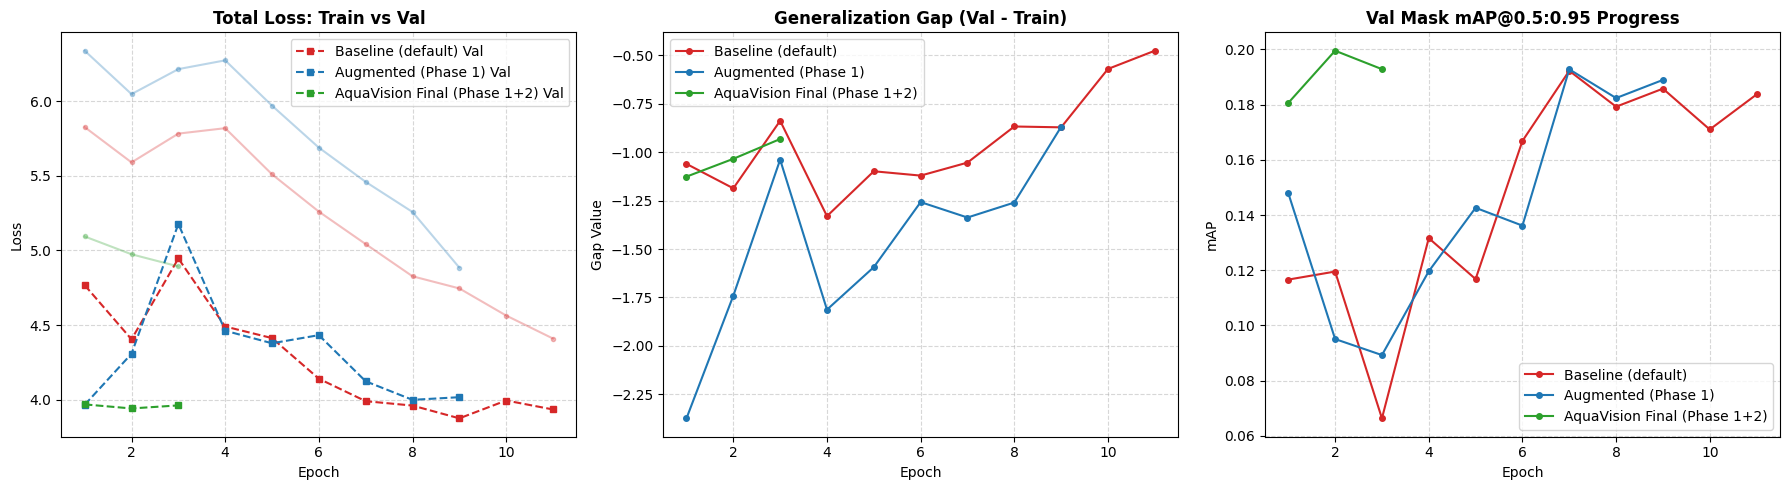

In [23]:
import matplotlib.pyplot as plt
import os

# Create a multi-panel final comparison plot for all three arms
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

arms_3 = ["default", "aug_single", "aug_single_late"]
labels_3 = {"default": "Baseline (default)", "aug_single": "Augmented (Phase 1)", "aug_single_late": "AquaVision Final (Phase 1+2)"}
colors_3 = {"default": "tab:red", "aug_single": "tab:blue", "aug_single_late": "tab:green"}

for arm in arms_3:
    run_path = f"{RUNS}/segmenter_{arm}_{TAG}" if arm != "aug_single_late" else f"{RUNS}/segmenter_aug_single_{TAG}_late"
    csv_path = f"{run_path}/results.csv"
    if os.path.exists(csv_path):
        df_arm = pd.read_csv(csv_path)
        df_arm.columns = df_arm.columns.str.strip()
        _, tr, va = loss_cols(df_arm)
        ep = df_arm["epoch"]

        # Plot 1: Total Val Loss
        ax[0].plot(ep, va, "--s", ms=4, color=colors_3[arm], label=f"{labels_3[arm]} Val")
        ax[0].plot(ep, tr, "-o", ms=3, alpha=0.3, color=colors_3[arm])

        # Plot 2: Generalization Gap (Val - Train Loss)
        ax[1].plot(ep, va - tr, "-o", ms=4, color=colors_3[arm], label=labels_3[arm])

        # Plot 3: Validation Mask mAP 50-95
        ax[2].plot(ep, df_arm["metrics/mAP50-95(M)"], "-o", ms=4, color=colors_3[arm], label=labels_3[arm])

ax[0].set_title("Total Loss: Train vs Val", fontsize=12, fontweight='bold')
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].grid(True, linestyle="--", alpha=0.5)
ax[0].legend()

ax[1].set_title("Generalization Gap (Val - Train)", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Gap Value")
ax[1].grid(True, linestyle="--", alpha=0.5)
ax[1].legend()

ax[2].set_title("Val Mask mAP@0.5:0.95 Progress", fontsize=12, fontweight='bold')
ax[2].set_xlabel("Epoch")
ax[2].set_ylabel("mAP")
ax[2].grid(True, linestyle="--", alpha=0.5)
ax[2].legend()

plt.tight_layout()

# Save locally and to Drive report assets
plt.savefig(f"{RUNS}/three_arms_loss_compare_{TAG}.png", dpi=300)
if os.path.isdir(ra):
    plt.savefig(f"{ra}/three_arms_loss_compare_{TAG}.png", dpi=300)
    print(f"[Success] Saved final 3-arm comparison graph to {ra}/three_arms_loss_compare_{TAG}.png")
else:
    print(f"[Note] Saved final comparison graph locally to {RUNS}/three_arms_loss_compare_{TAG}.png")

plt.show()

## 7 - Baseline vs AquaVision recipe + overfit check + sanity images

TEST split, per arm


,default,aug_single,default,aug_single,default,aug_single,default,aug_single,default,aug_single,default,aug_single,default,aug_single,default,aug_single
,box_mAP50,box_mAP50,box_mAP50-95,box_mAP50-95,mask_mAP50,mask_mAP50,mask_mAP50-95,mask_mAP50-95,box_P,box_P,box_R,box_R,mean_box_IoU,mean_box_IoU,mask_boundary_err,mask_boundary_err
subset,,,,,,,,,,,,,,,,
ALL (test),0.3305,0.2949,0.1958,0.1687,0.2940,0.2764,0.1532,0.1507,0.5333,0.4378,0.3921,0.3646,0.3427,0.3377,0.0041,0.0048
"brackish (test, n=2141)",0.0625,0.0505,0.0297,0.0240,0.0373,0.0364,0.0123,0.0131,0.1756,0.1431,0.2392,0.2633,0.1878,0.1908,0.0047,0.0066
"deepfish (test, n=658)",0.5674,0.5459,0.3501,0.3137,0.5333,0.5336,0.2935,0.2961,0.8480,0.7669,0.5251,0.5055,0.4462,0.4280,0.0040,0.0042
clean half (test),0.2789,0.2787,0.1914,0.1808,0.2543,0.2670,0.1564,0.1739,0.4693,0.3852,0.2836,0.3354,0.2581,0.3054,0.0030,0.0040
turbid half (test),0.7295,0.6329,0.4173,0.3391,0.6453,0.5867,0.3220,0.2902,0.7525,0.6690,0.6890,0.5804,0.5803,0.5256,0.0045,0.0051


Gain of aug_single over default (positive = augmentation helps; for mask_boundary_err NEGATIVE is better)


,box_mAP50,box_mAP50-95,mask_mAP50,mask_mAP50-95,box_P,box_R,mean_box_IoU,mask_boundary_err
subset,,,,,,,,
ALL (test),-0.0356,-0.0271,-0.0176,-0.0025,-0.0955,-0.0275,-0.0050,0.0007
"brackish (test, n=2141)",-0.0120,-0.0057,-0.0009,0.0008,-0.0325,0.0241,0.0030,0.0019
"deepfish (test, n=658)",-0.0215,-0.0364,0.0003,0.0026,-0.0811,-0.0196,-0.0182,0.0002
clean half (test),-0.0002,-0.0106,0.0127,0.0175,-0.0841,0.0518,0.0473,0.0010
turbid half (test),-0.0966,-0.0782,-0.0586,-0.0318,-0.0835,-0.1086,-0.0547,0.0006


turbid minus clean (closer to 0 = more robust)


,default,aug_single
box_mAP50-95,0.2259,0.1583
mask_mAP50-95,0.1656,0.1163


copied comparison + gain tables to report_assets

[default] epochs run: 11 | best epoch 7 | val mask mAP50-95 0.192 | val seg loss at best 1.597 -> last 1.588


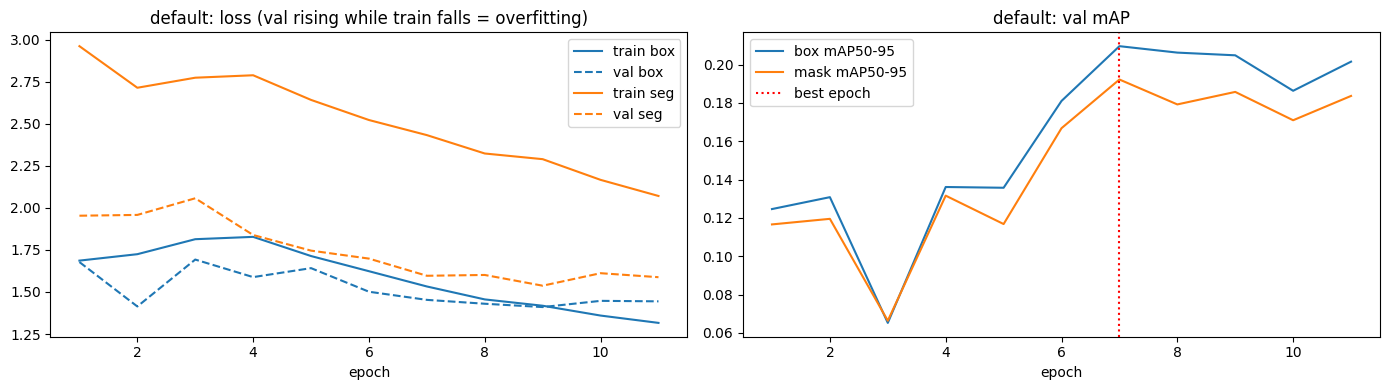


[aug_single] epochs run: 9 | best epoch 7 | val mask mAP50-95 0.193 | val seg loss at best 1.684 -> last 1.643


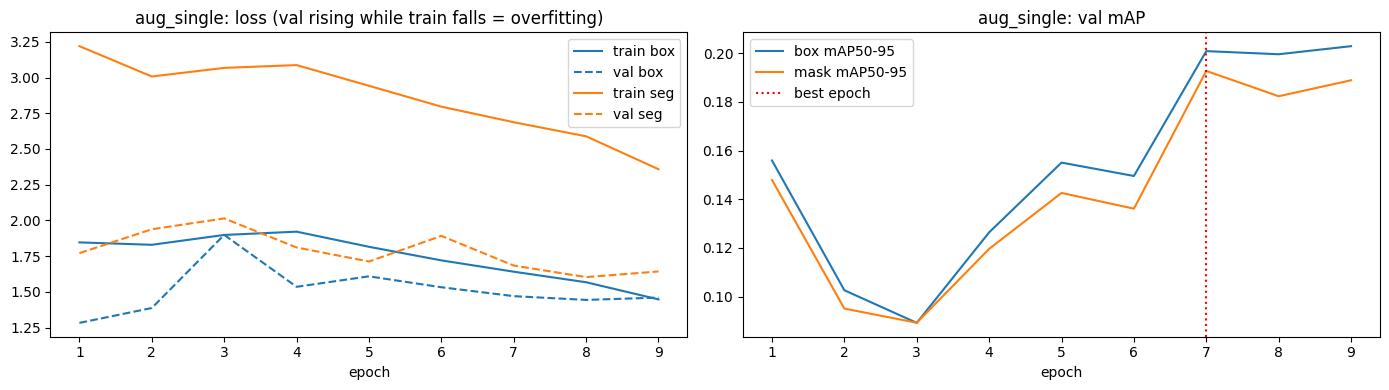

default train_batch0.jpg


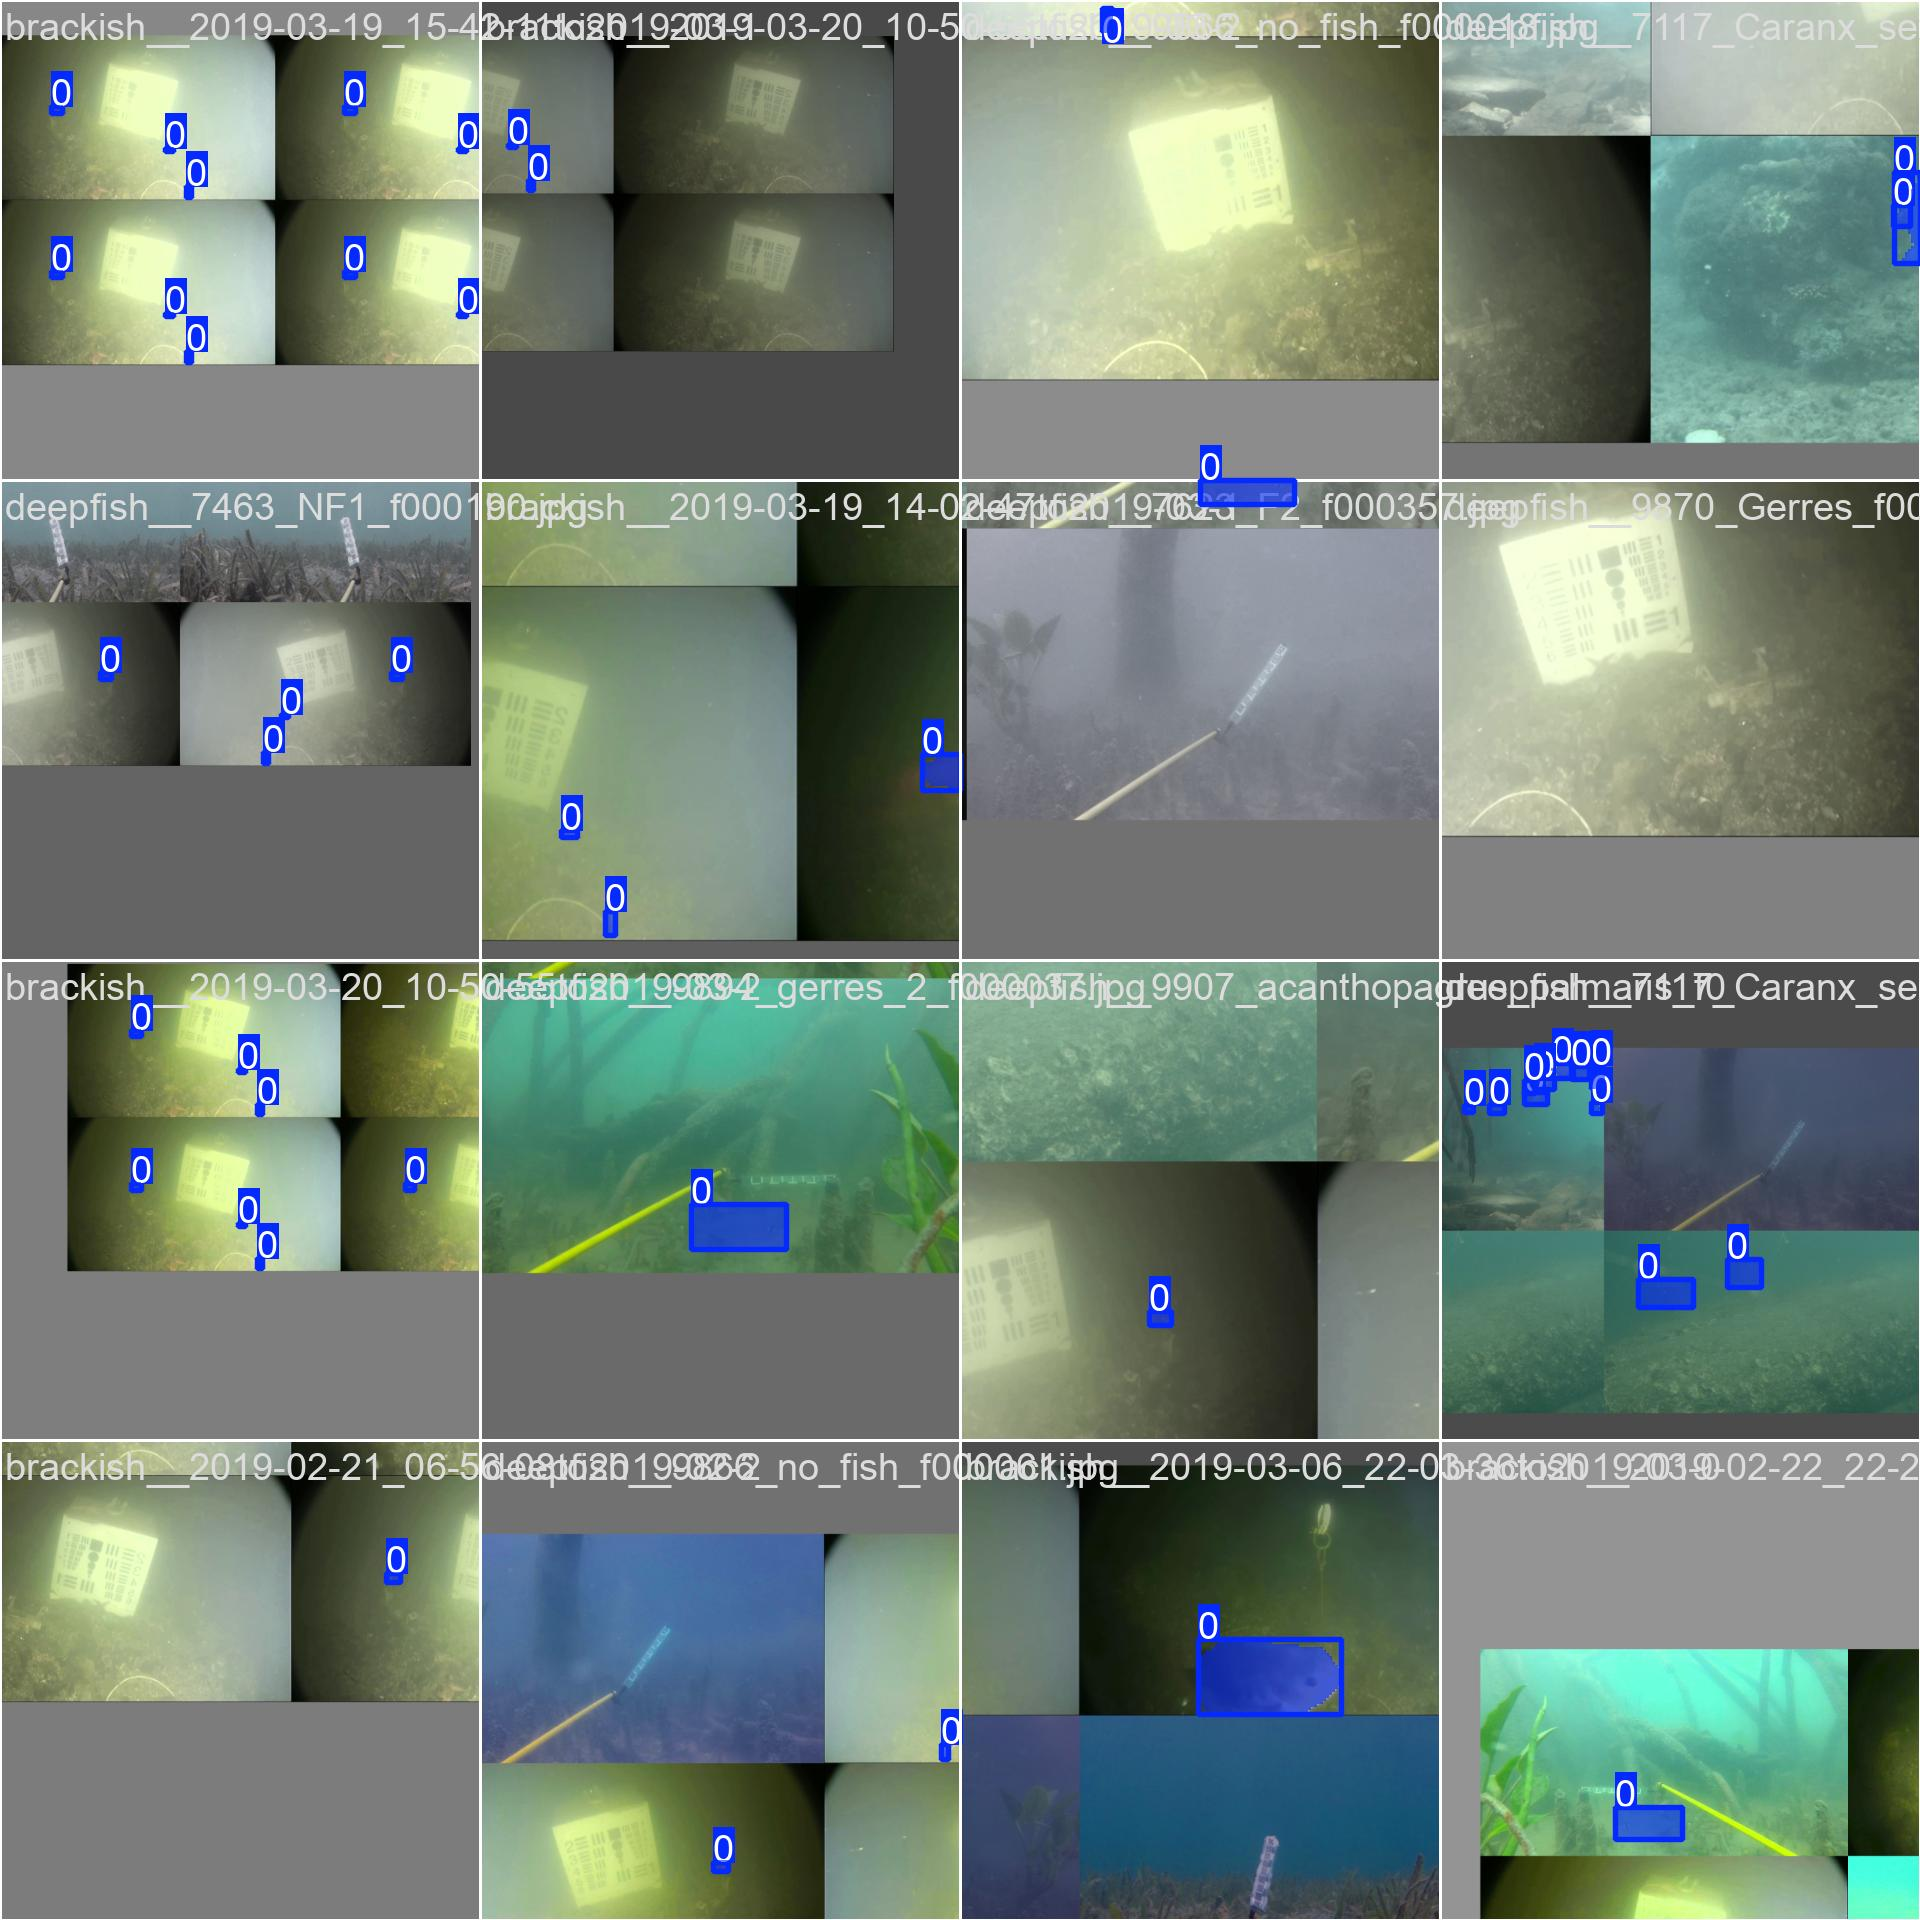

default val_batch0_labels.jpg


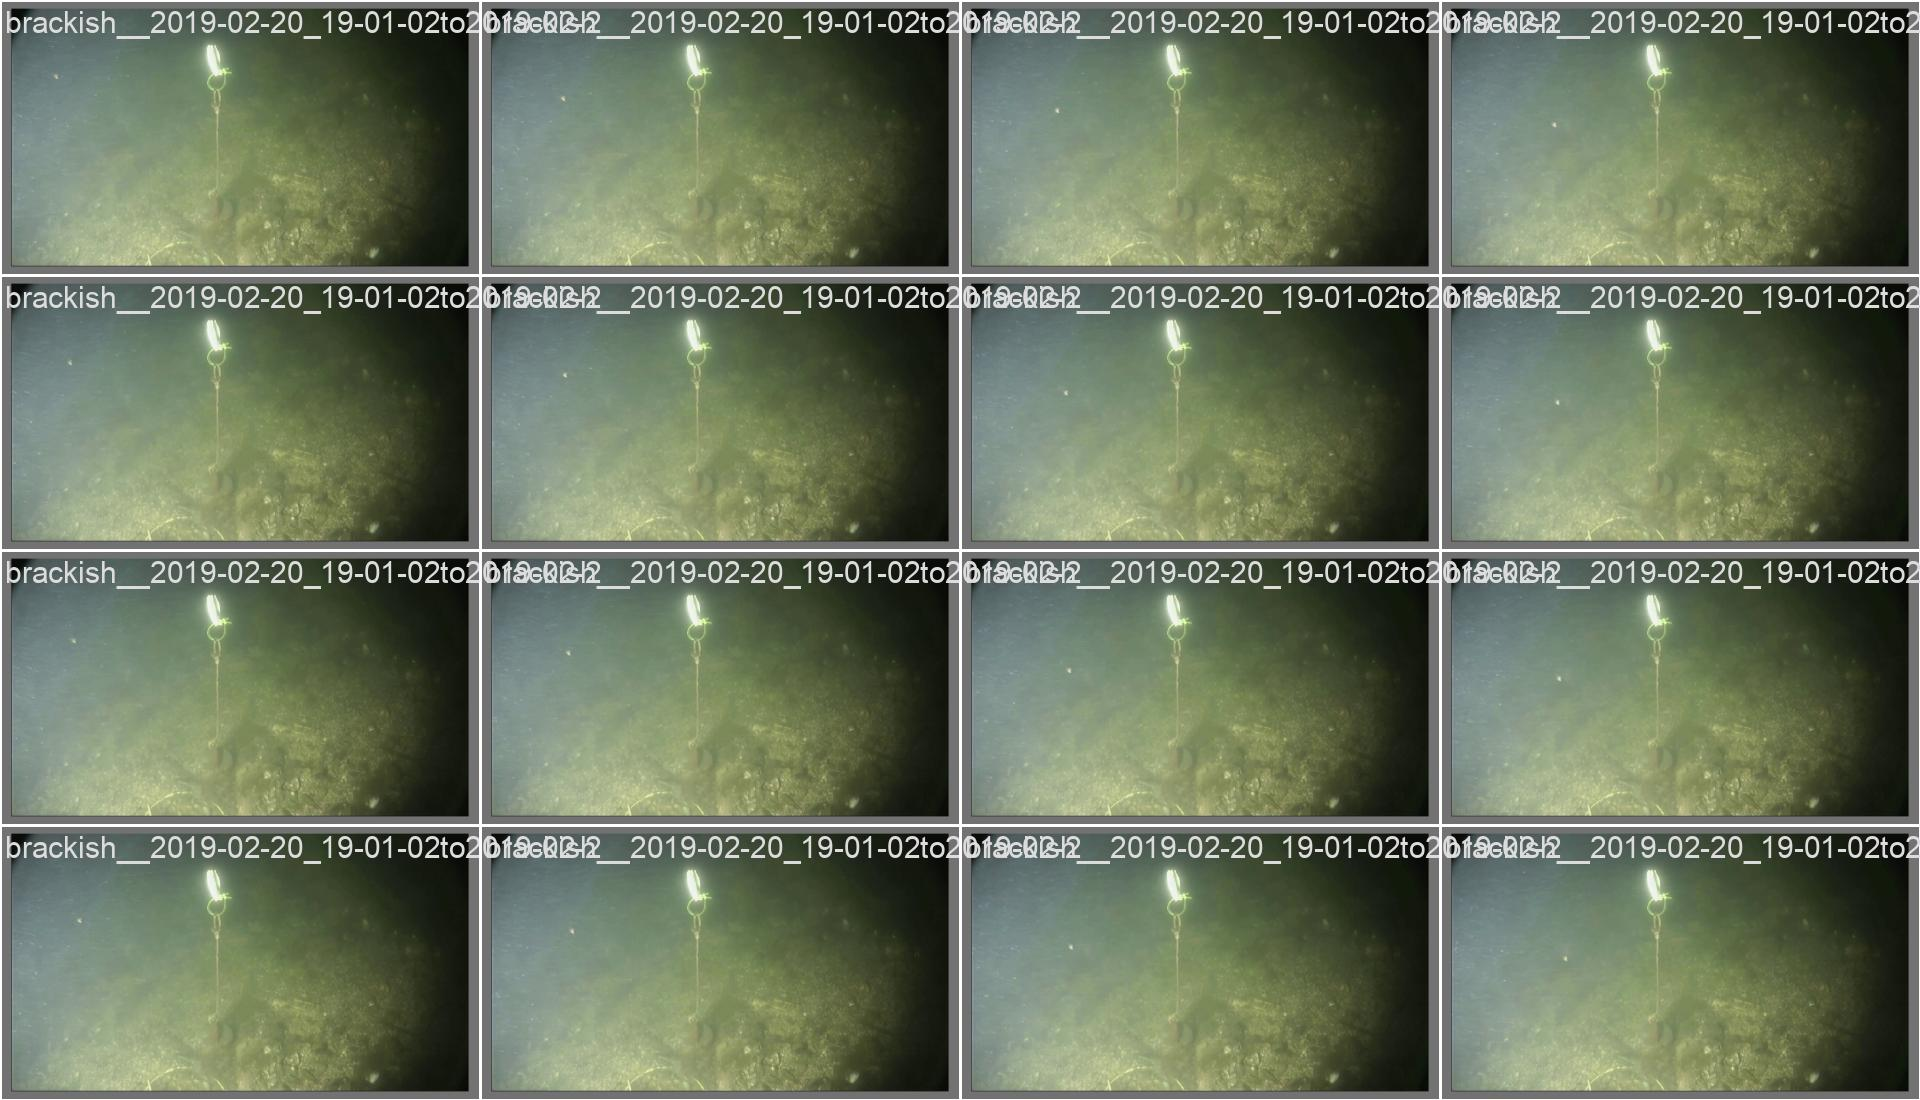

default val_batch0_pred.jpg


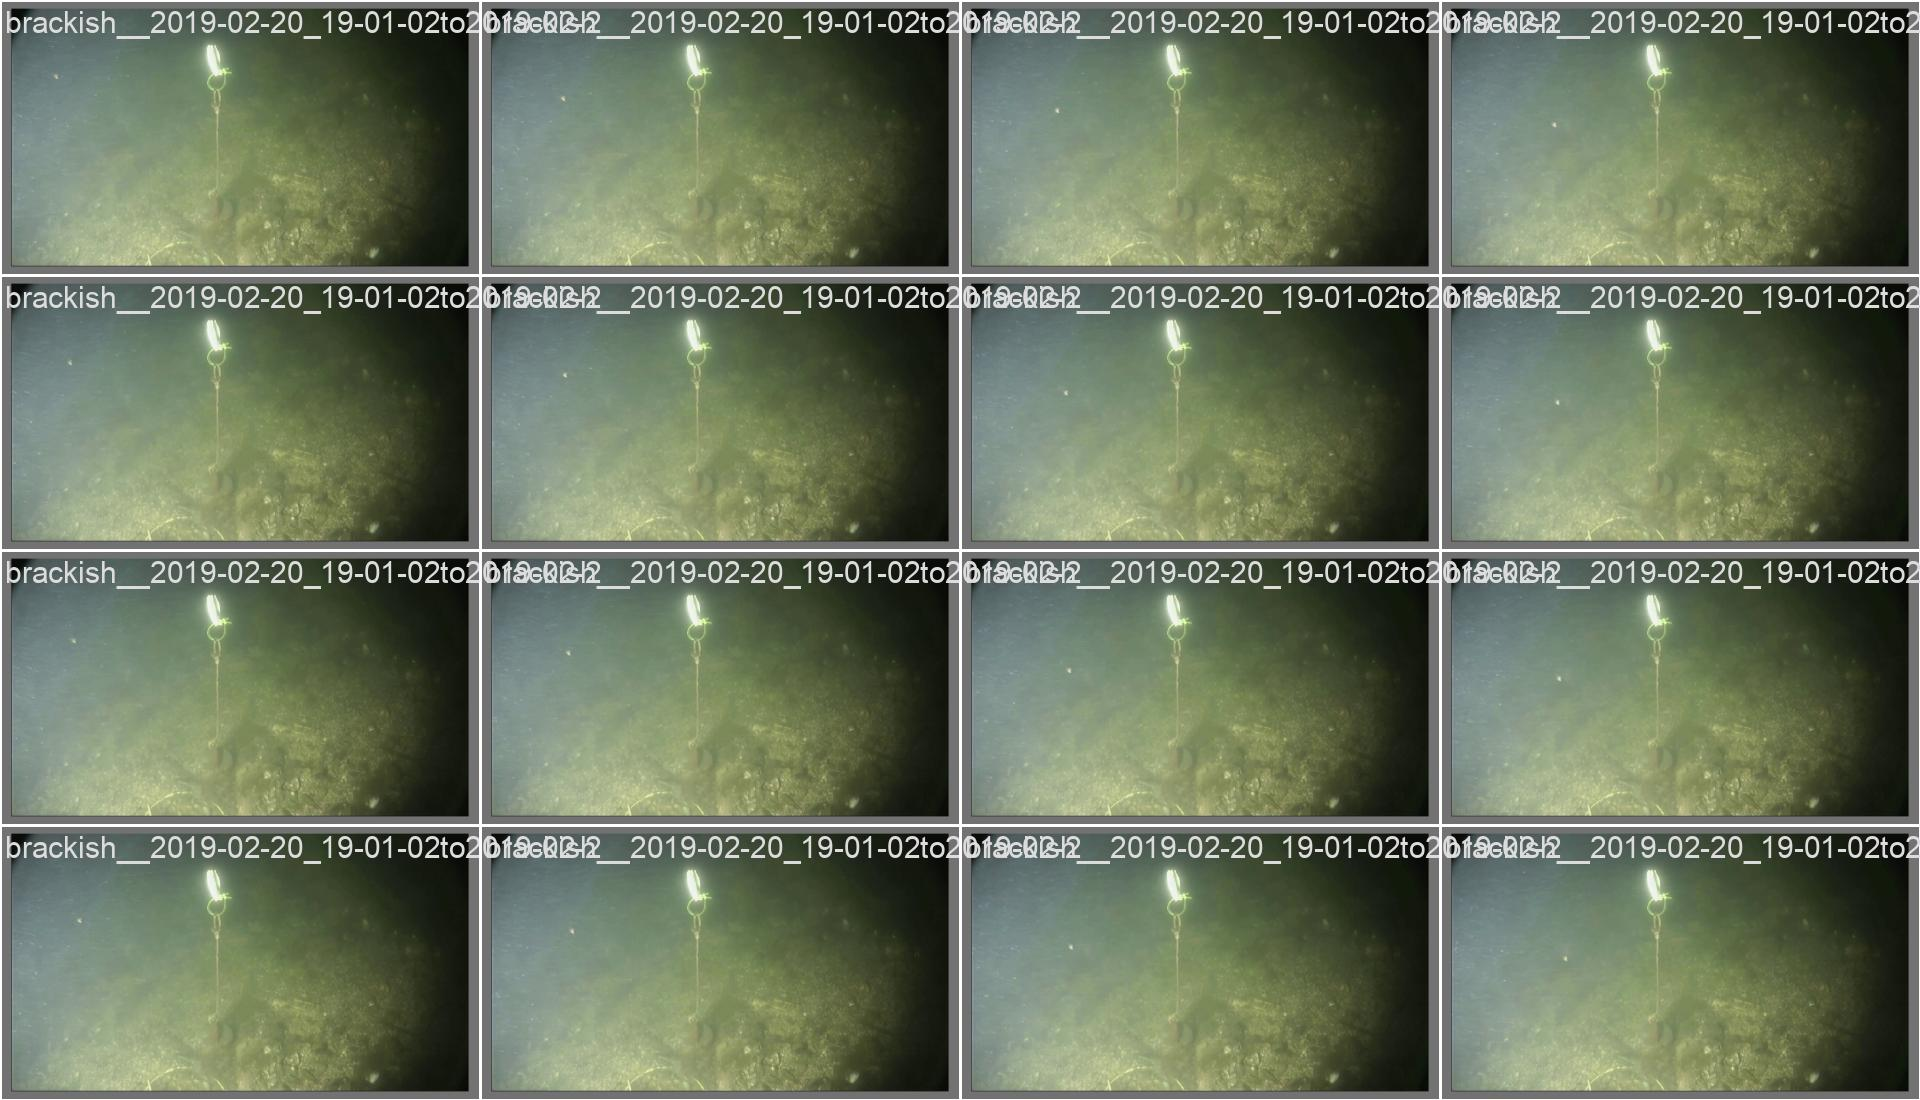

aug_single train_batch0.jpg


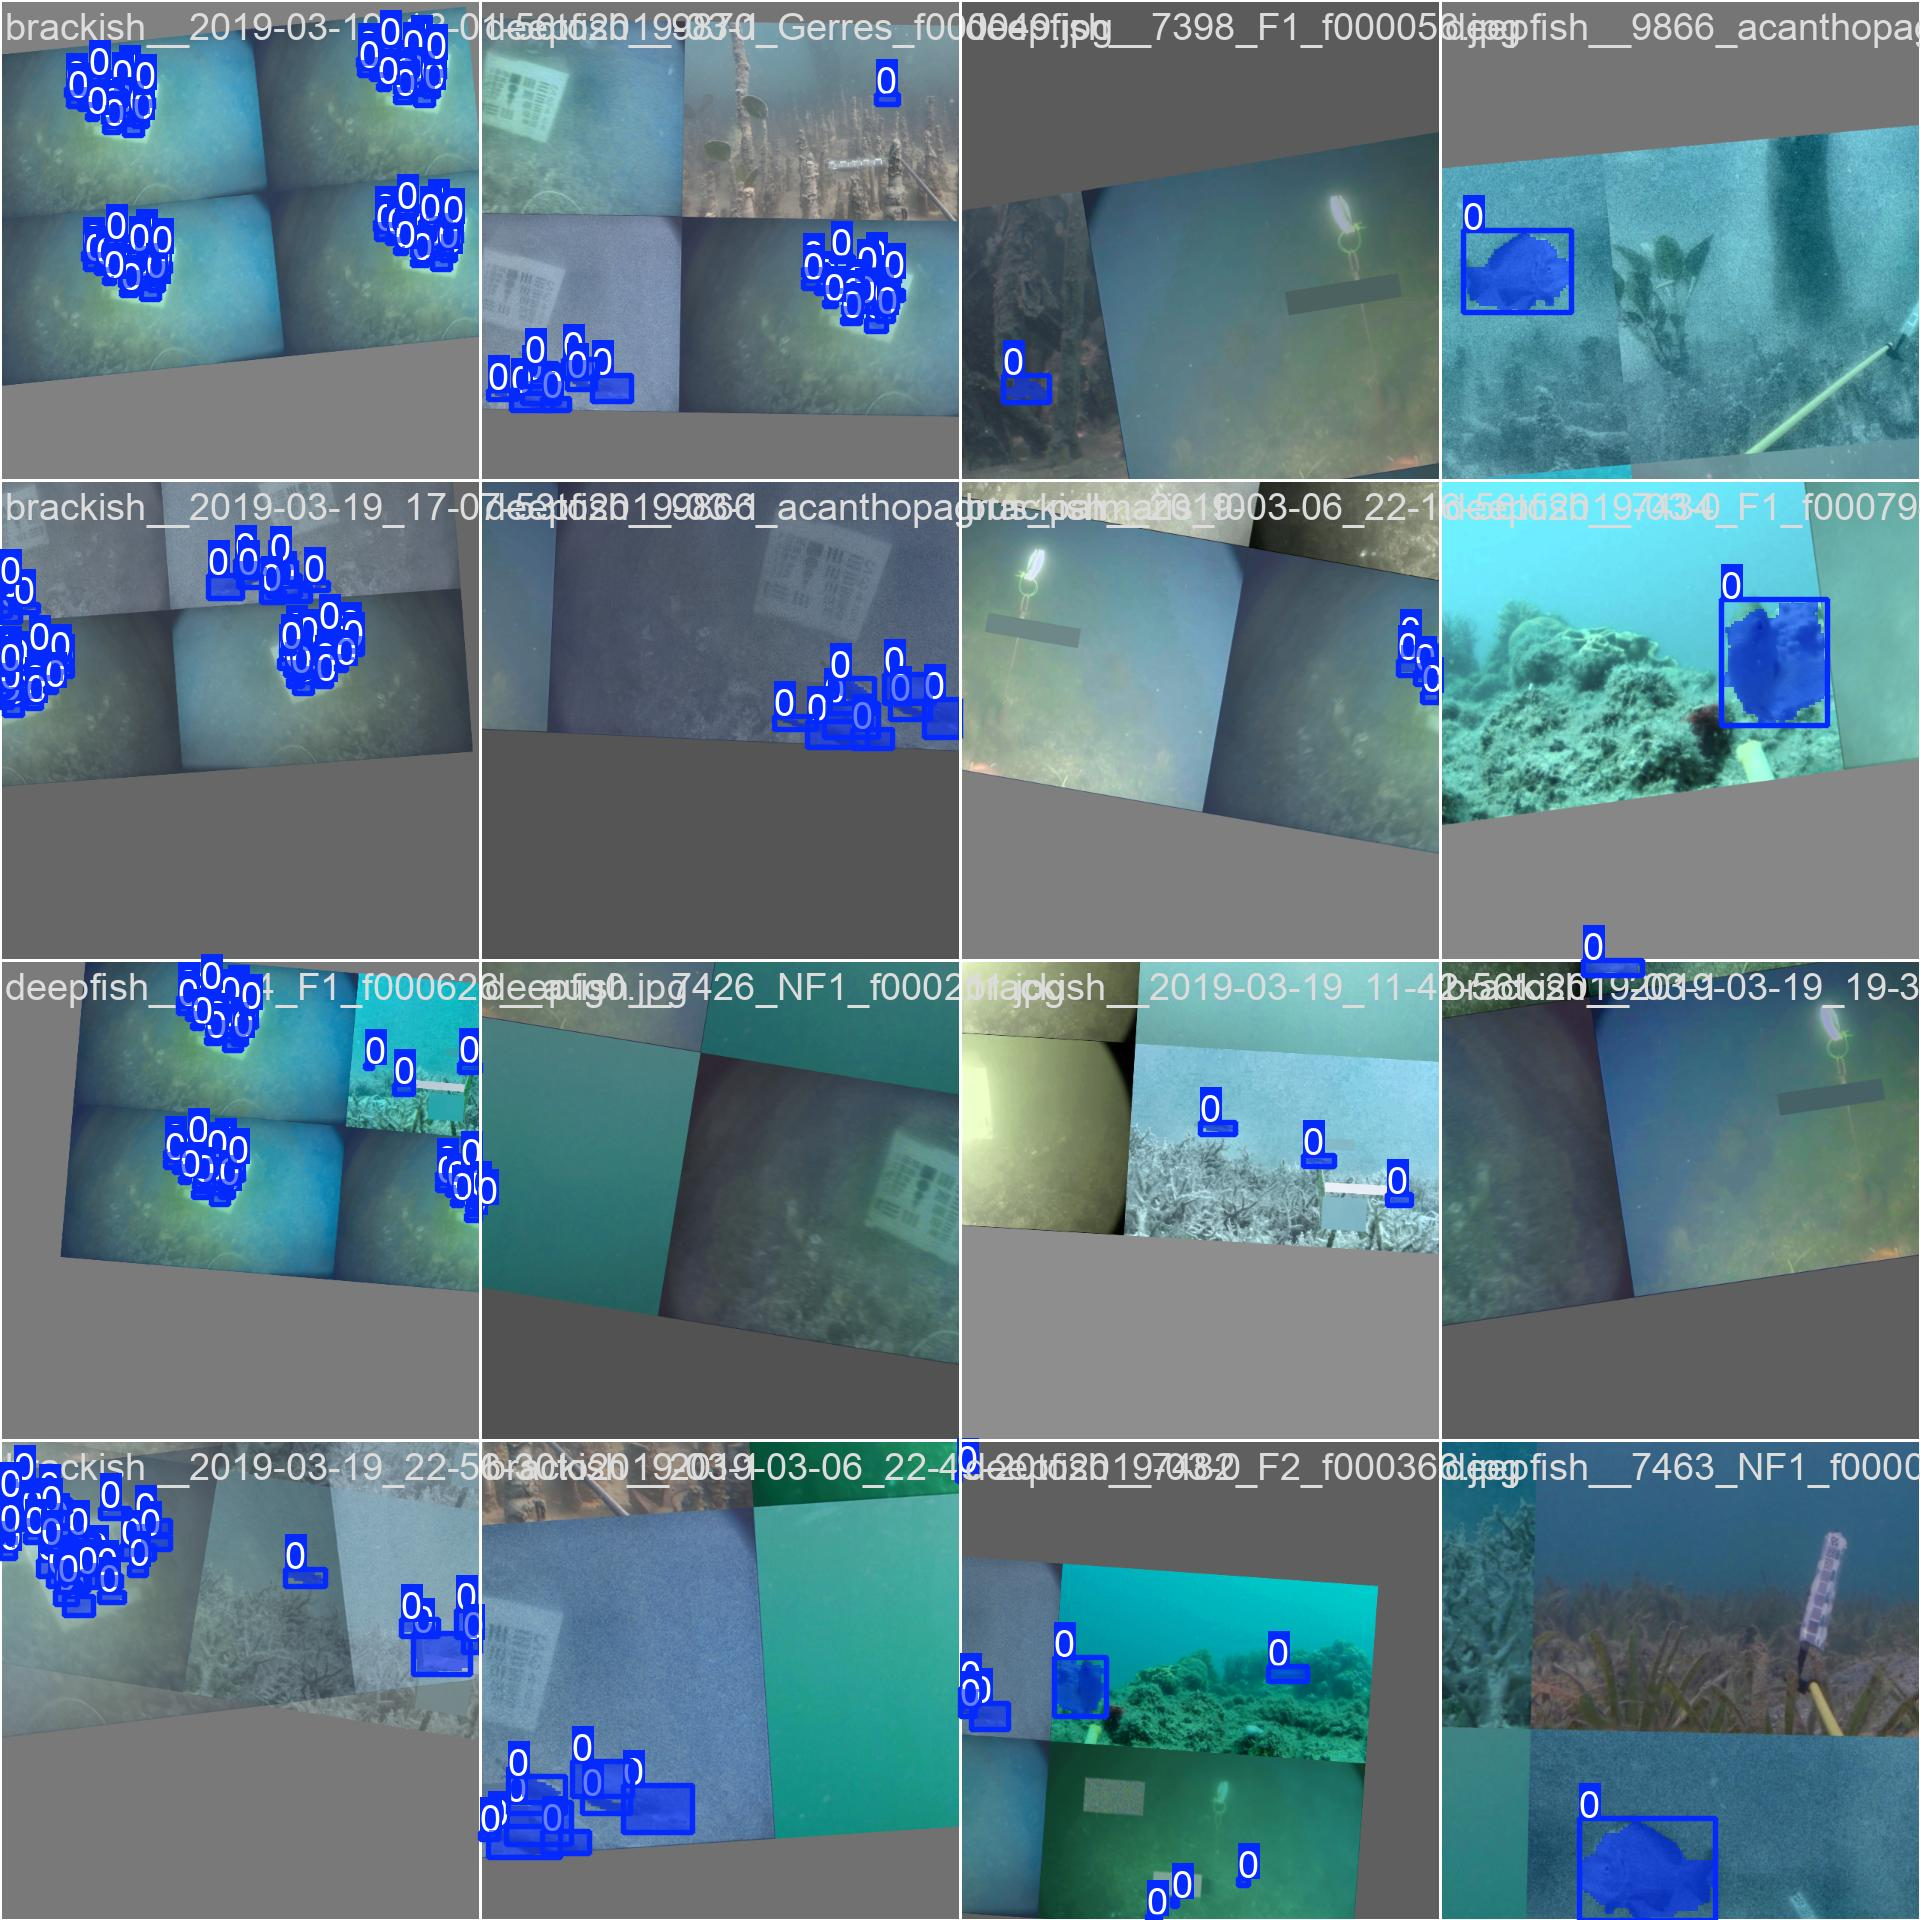

aug_single val_batch0_labels.jpg


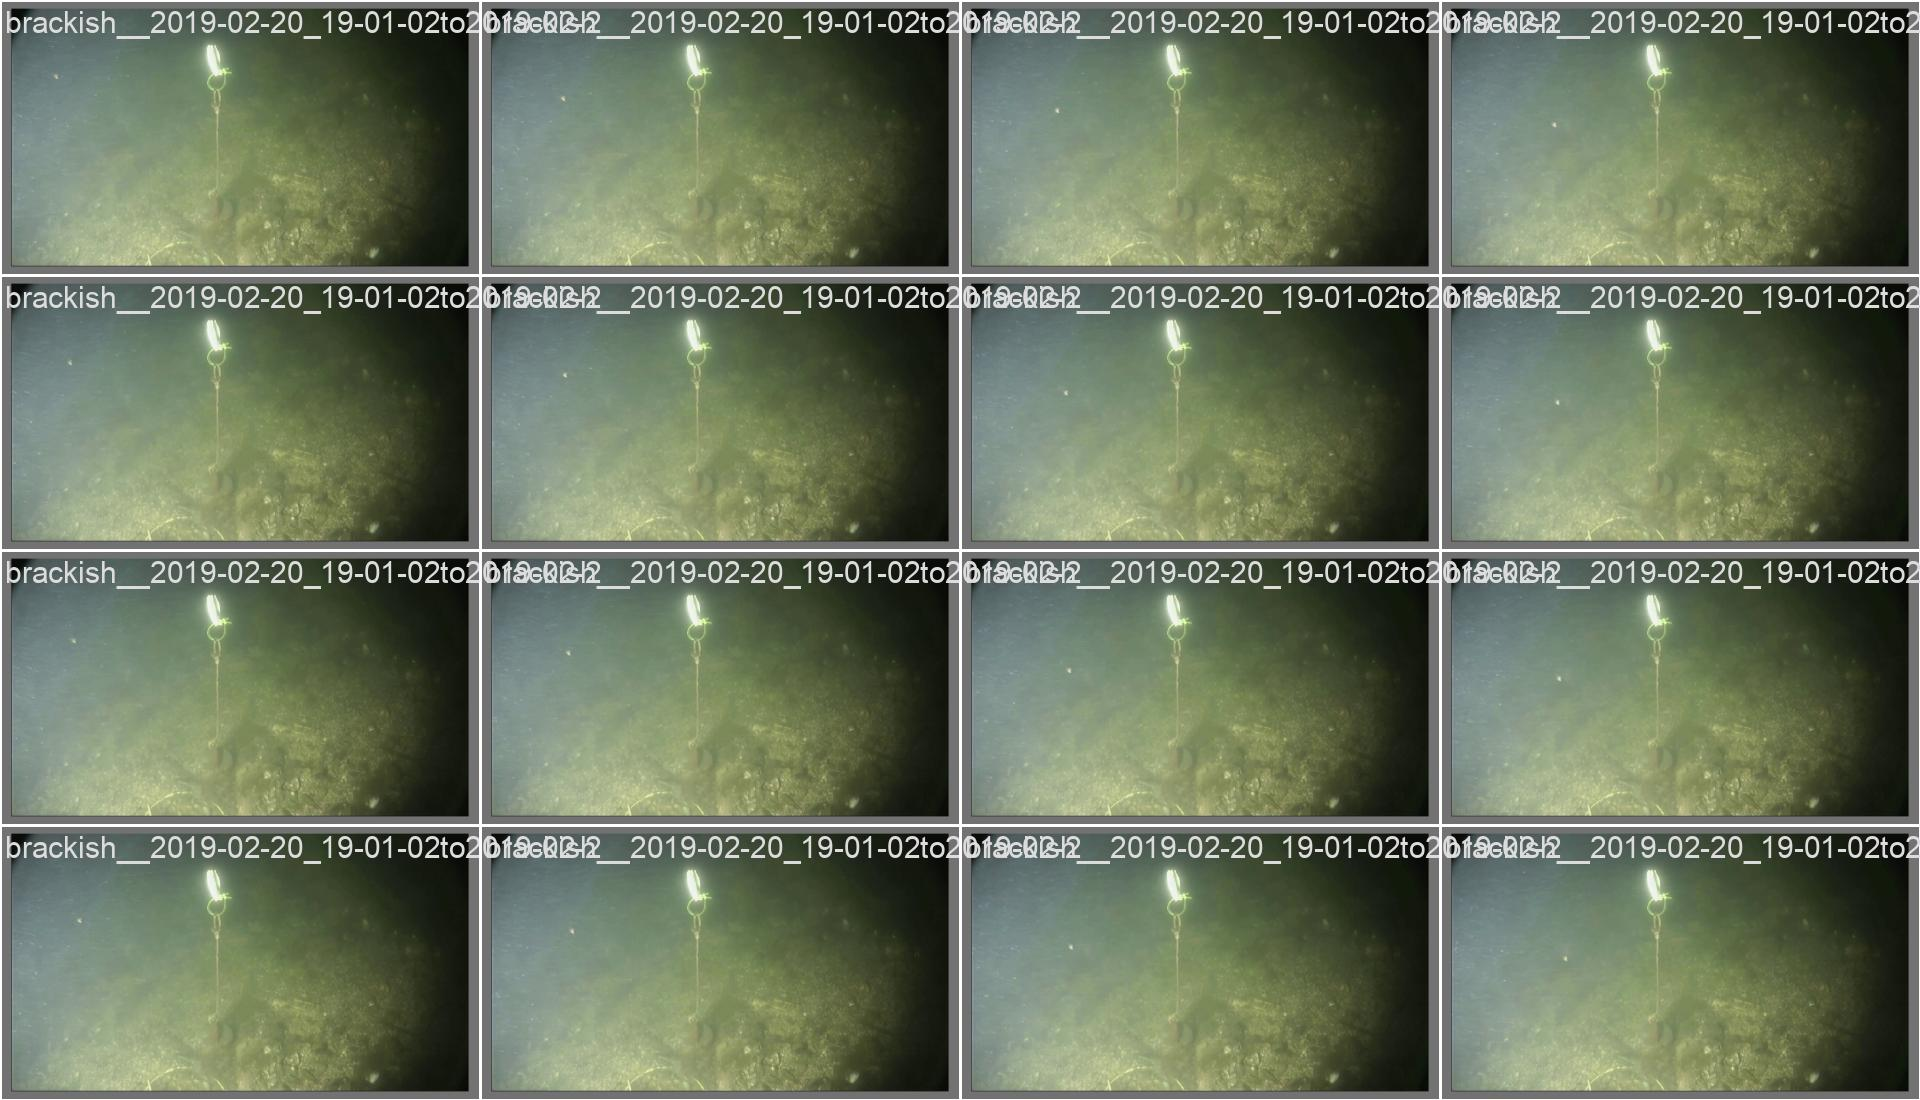

aug_single val_batch0_pred.jpg


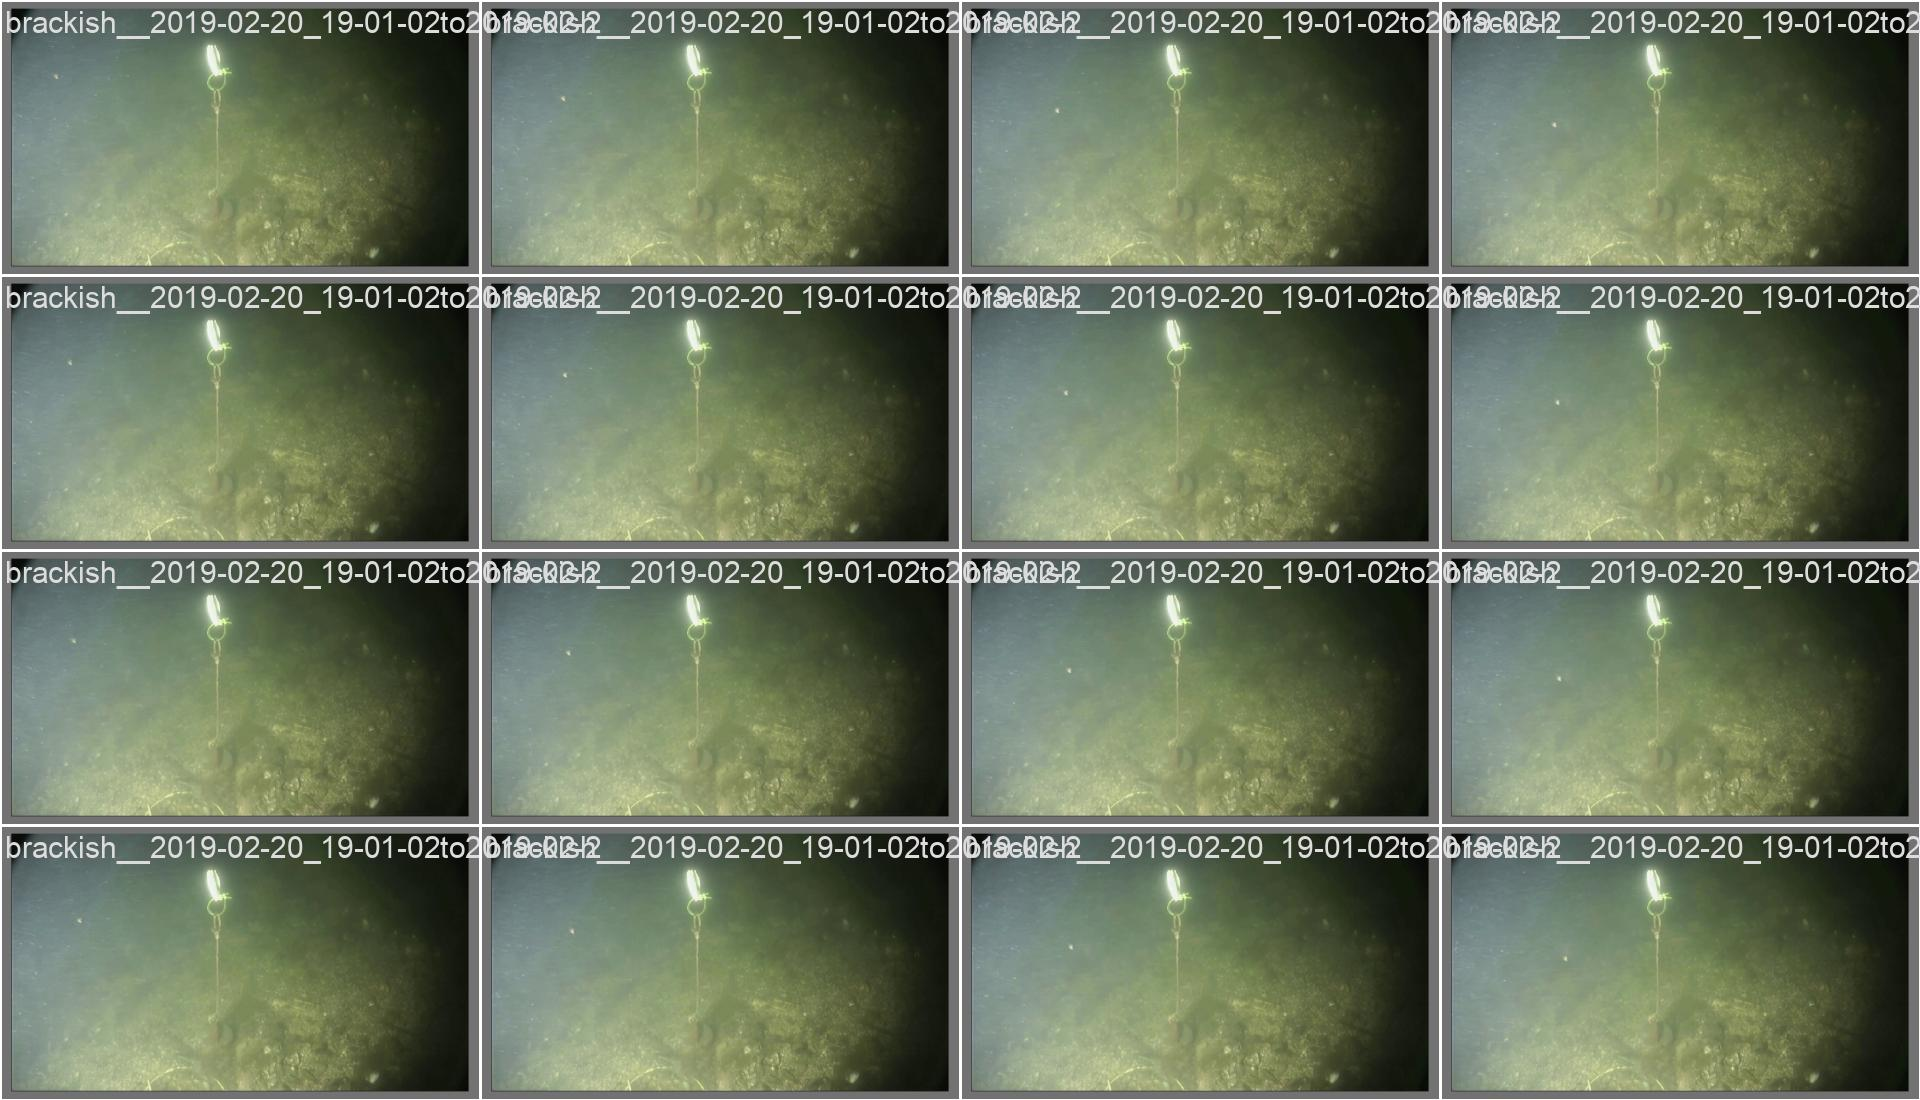

OK      /content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h/weights/best.pt (20.5 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h/results.csv (0.0 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h/test_metrics.csv (0.0 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h/overfit_check.png (0.1 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h/weights/best.pt (20.5 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h/results.csv (0.0 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h/test_metrics.csv (0.0 MB)
OK      /content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h/overfit_check.png (0.1 MB)


In [20]:
import matplotlib.pyplot as plt
tabs = {a: pd.read_csv(f"{RUN_DIRS[a]}/test_metrics.csv", index_col="subset") for a in ARMS}
cmp = pd.concat(tabs, axis=1)
keep = ["box_mAP50", "box_mAP50-95", "mask_mAP50", "mask_mAP50-95", "box_P", "box_R", "mean_box_IoU", "mask_boundary_err"]
print("TEST split, per arm"); display(cmp.loc[:, [(a, k) for k in keep for a in ARMS]])
a, b = ARMS
gain = (tabs[b][keep] - tabs[a][keep]).round(4)
print(f"Gain of {b} over {a} (positive = augmentation helps; for mask_boundary_err NEGATIVE is better)"); display(gain)

# clean -> turbid drop per arm (report Sec. 6.1: smaller drop = more turbidity-robust)
cl = [s for s in tabs[a].index if s.startswith("clean")]; tu = [s for s in tabs[a].index if s.startswith("turbid")]
if cl and tu:
    drop = pd.DataFrame({arm: (tabs[arm].loc[tu[0], ["box_mAP50-95", "mask_mAP50-95"]] - tabs[arm].loc[cl[0], ["box_mAP50-95", "mask_mAP50-95"]]) for arm in ARMS}).round(4)
    print("turbid minus clean (closer to 0 = more robust)"); display(drop)

cmp.to_csv(f"{RUNS}/comparison_{TAG}.csv"); gain.to_csv(f"{RUNS}/gain_{TAG}.csv")
ra = f"{DRIVE}/report_assets"
if os.path.isdir(ra):
    for f in (f"comparison_{TAG}.csv", f"gain_{TAG}.csv"): shutil_ok = os.system(f'cp "{RUNS}/{f}" "{ra}/"')
    print("copied comparison + gain tables to report_assets")

# overfit check per arm
for arm in ARMS:
    df = pd.read_csv(f"{RUN_DIRS[arm]}/results.csv"); df.columns = df.columns.str.strip()
    i = df["metrics/mAP50-95(M)"].idxmax()
    print(f"\n[{arm}] epochs run: {int(df['epoch'].max())} | best epoch {int(df.loc[i,'epoch'])} | val mask mAP50-95 {df.loc[i,'metrics/mAP50-95(M)']:.3f}"
          f" | val seg loss at best {df.loc[i,'val/seg_loss']:.3f} -> last {df['val/seg_loss'].iloc[-1]:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for k, c in (("box", "tab:blue"), ("seg", "tab:orange")):
        ax[0].plot(df["epoch"], df[f"train/{k}_loss"], c=c, label=f"train {k}"); ax[0].plot(df["epoch"], df[f"val/{k}_loss"], c=c, ls="--", label=f"val {k}")
    ax[0].set_title(f"{arm}: loss (val rising while train falls = overfitting)"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="box mAP50-95"); ax[1].plot(df["epoch"], df["metrics/mAP50-95(M)"], label="mask mAP50-95")
    ax[1].axvline(df.loc[i, "epoch"], c="r", ls=":", label="best epoch"); ax[1].set_title(f"{arm}: val mAP"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(f"{RUN_DIRS[arm]}/overfit_check.png", dpi=150); plt.show()

# sanity images: do the training masks sit on real fish, are predictions sensible?
for arm in ARMS:
    for f in ("train_batch0.jpg", "val_batch0_labels.jpg", "val_batch0_pred.jpg"):
        p = f"{RUN_DIRS[arm]}/{f}"
        if os.path.exists(p): print(arm, f); display(Image(p, width=800))
for arm in ARMS:
    for f in ("weights/best.pt", "results.csv", "test_metrics.csv", "overfit_check.png"):
        p = f"{RUN_DIRS[arm]}/{f}"; print(f"OK      {p} ({os.path.getsize(p)/1e6:.1f} MB)" if os.path.exists(p) else f"MISSING {p}")

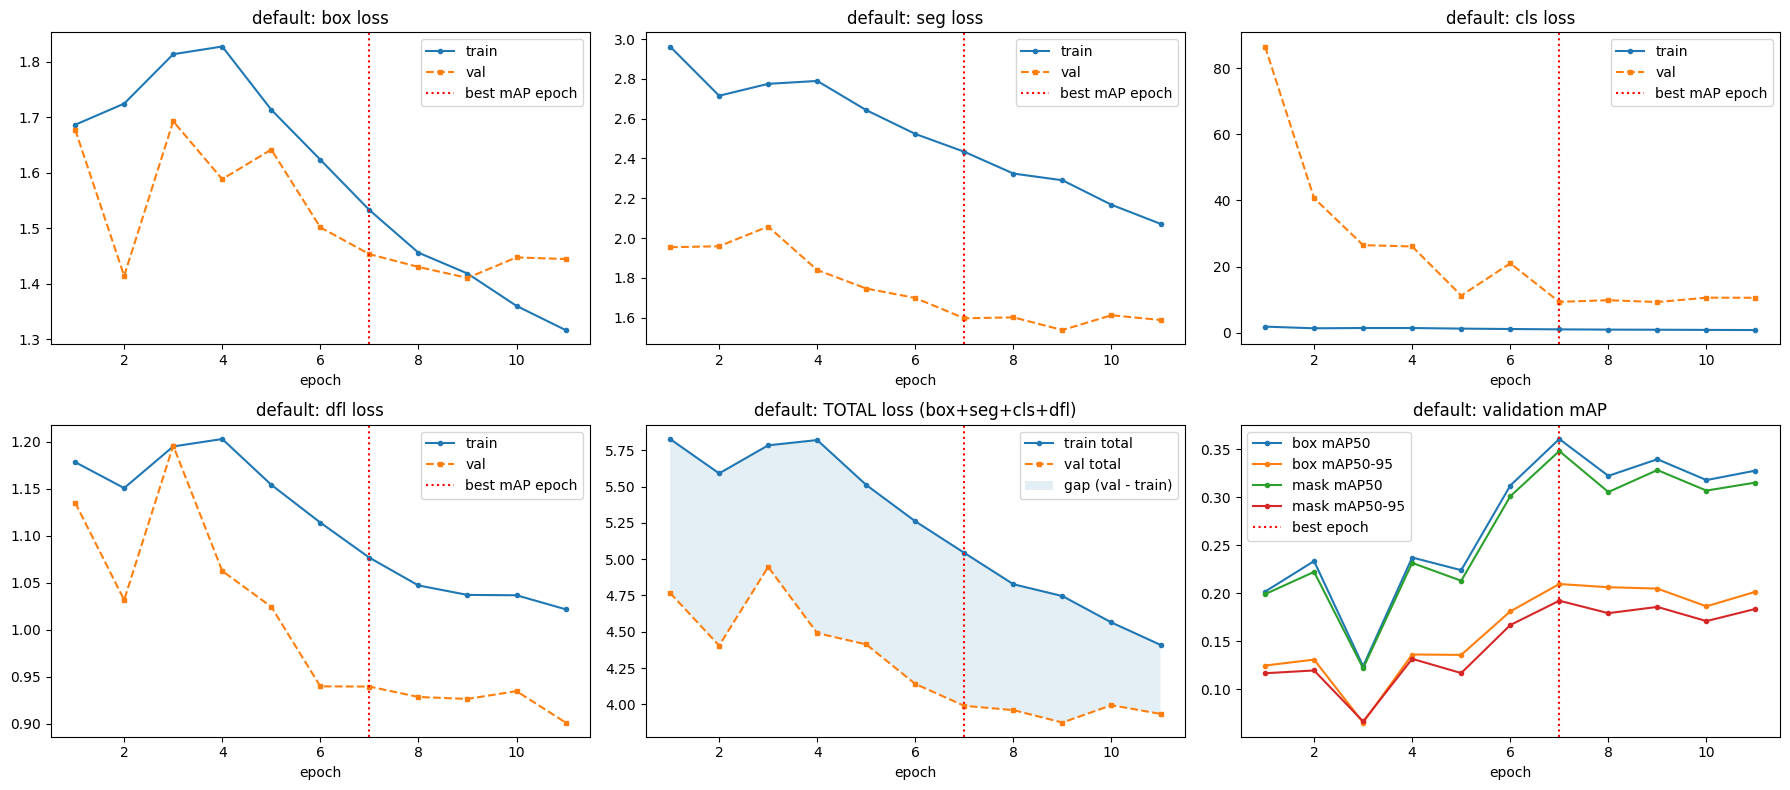

saved /content/drive/MyDrive/aquavision/runs/segmenter_default_pdf3h/loss_curves.png


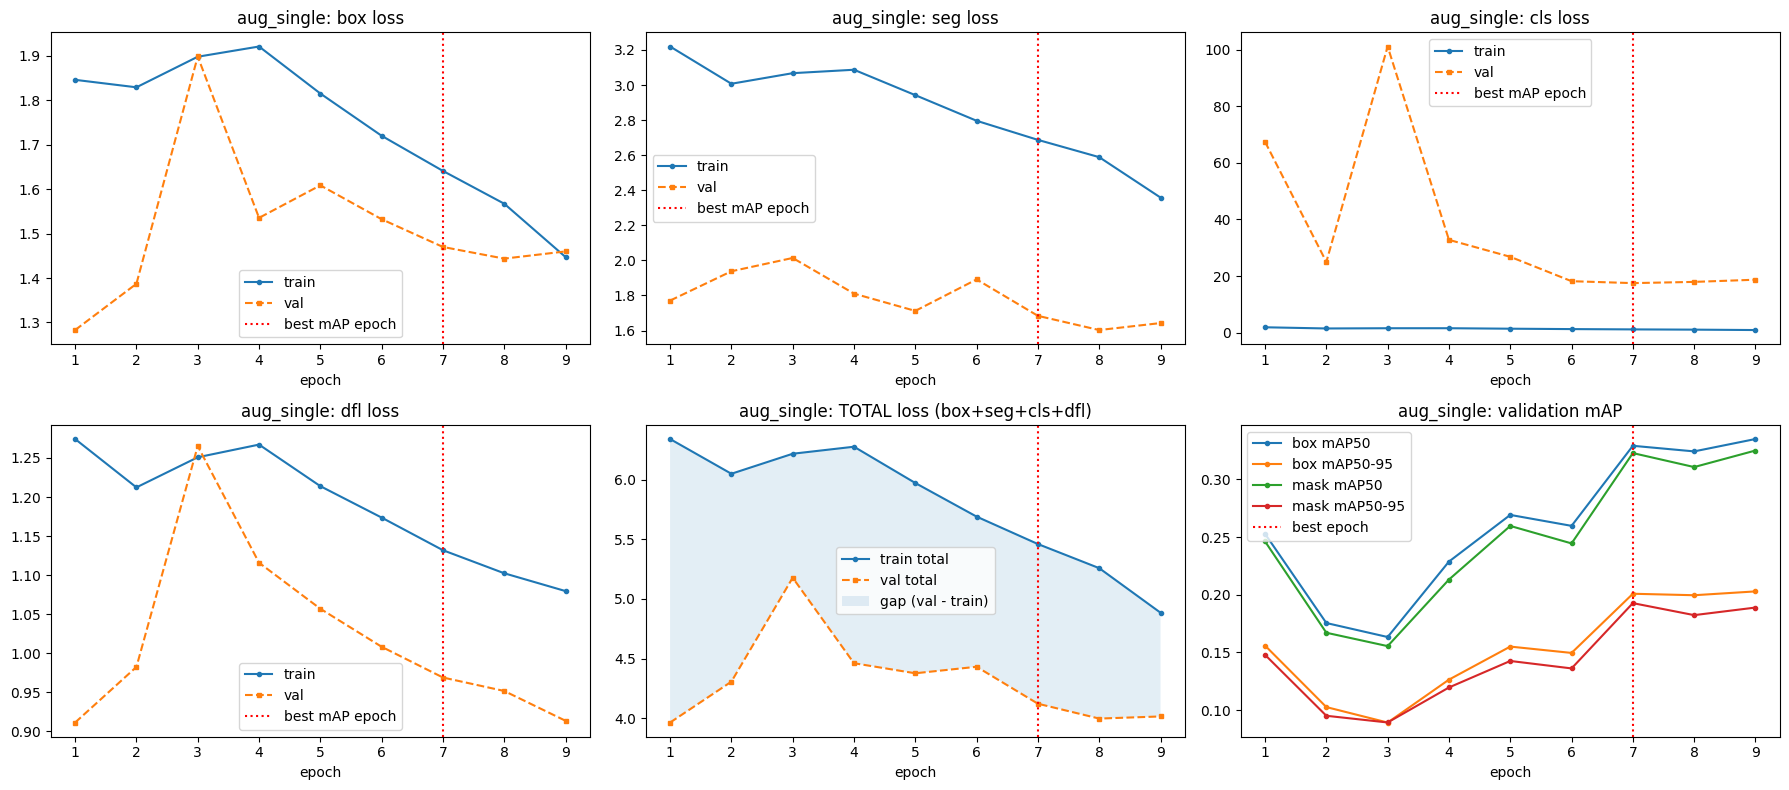

saved /content/drive/MyDrive/aquavision/runs/segmenter_aug_single_pdf3h/loss_curves.png


arm,default,aug_single
epochs,11,9
best_epoch,7,7
best_mask_mAP50_95,0.1922,0.1928
last_mask_mAP50_95,0.1837,0.1889
val_loss_min,3.8743,3.9651
val_loss_last,3.9338,4.0162
train_loss_last,4.4093,4.885
status,NOT overfitting - plateau / stable (short run: indicative only),NOT overfitting - plateau / stable (short run: indicative only)
flags,-,-


[default] NOT overfitting - plateau / stable (short run: indicative only)
   reasons: <Flags(allows_duplicate_labels=True)>
[aug_single] NOT overfitting - plateau / stable (short run: indicative only)
   reasons: <Flags(allows_duplicate_labels=True)>


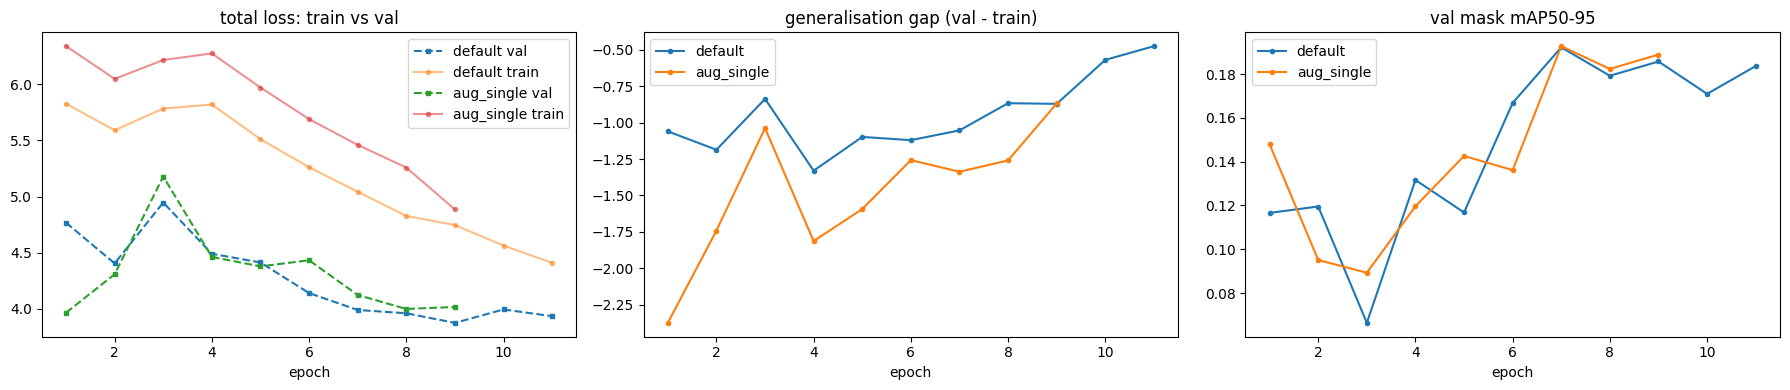

In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def load_results(run_dir):
    df = pd.read_csv(f"{run_dir}/results.csv"); df.columns = df.columns.str.strip(); return df

def loss_cols(df):
    parts = [k for k in ("box", "seg", "cls", "dfl") if f"train/{k}_loss" in df and f"val/{k}_loss" in df]
    use = [k for k in ("box", "seg", "dfl") if k in parts]          # cls excluded from the total (normalisation artifact)
    tr = df[[f"train/{k}_loss" for k in use]].sum(axis=1); va = df[[f"val/{k}_loss" for k in use]].sum(axis=1)
    return parts, tr, va

def verdict(df, tail=3):
    parts, tr, va = loss_cols(df)
    m = df["metrics/mAP50-95(M)"]; best = int(m.idxmax()); last = len(df) - 1
    n = min(tail, len(df) - 1)
    tr_slope = np.polyfit(range(n + 1), tr.iloc[-(n + 1):], 1)[0] if n >= 1 else 0.0
    va_slope = np.polyfit(range(n + 1), va.iloc[-(n + 1):], 1)[0] if n >= 1 else 0.0
    va_rise = (va.iloc[-1] - va.min()) / va.min() * 100
    map_drop = (m.max() - m.iloc[-1]) / max(m.max(), 1e-9) * 100
    flags = []
    if va_slope / va.mean() > 0.01 and tr_slope < 0: flags.append("val loss rising (>1%/epoch) while train loss falling")
    if va_rise > 5: flags.append(f"val loss {va_rise:.1f}% above its minimum")
    if map_drop > 5 and best < last: flags.append(f"mask mAP50-95 {map_drop:.1f}% below its best (epoch {int(df.loc[best,'epoch'])})")
    if len(flags) >= 2:   status = "OVERFITTING"
    elif len(flags) == 1: status = "MILD / EARLY SIGNS of overfitting"
    elif m.iloc[-1] >= m.max() - 1e-4 and va_slope <= 0: status = "NOT overfitting - still improving (underfit)"
    else: status = "NOT overfitting - plateau / stable"
    if len(df) < 15: status += " (short run: indicative only)"
    return dict(arm=None, epochs=len(df), best_epoch=int(df.loc[best, "epoch"]), best_mask_mAP50_95=round(float(m.max()), 4),
                last_mask_mAP50_95=round(float(m.iloc[-1]), 4), val_loss_min=round(float(va.min()), 4), val_loss_last=round(float(va.iloc[-1]), 4),
                train_loss_last=round(float(tr.iloc[-1]), 4), status=status, flags="; ".join(flags) or "-")

rows = []
for arm in ARMS:
    df = load_results(RUN_DIRS[arm]); parts, tr, va = loss_cols(df); ep = df["epoch"]
    best = int(df["metrics/mAP50-95(M)"].idxmax())
    fig, ax = plt.subplots(2, 3, figsize=(18, 8)); ax = ax.ravel()
    for a, k in zip(ax[:len(parts)], parts):                       # each loss: train vs val
        a.plot(ep, df[f"train/{k}_loss"], "-o", ms=3, label="train"); a.plot(ep, df[f"val/{k}_loss"], "--s", ms=3, label="val")
        a.axvline(df.loc[best, "epoch"], c="r", ls=":", label="best mAP epoch"); a.set_title(f"{arm}: {k} loss"); a.set_xlabel("epoch"); a.legend()
    a = ax[4]; a.plot(ep, tr, "-o", ms=3, label="train total"); a.plot(ep, va, "--s", ms=3, label="val total")
    a.fill_between(ep, tr, va, alpha=0.12, label="gap (val - train)"); a.axvline(df.loc[best, "epoch"], c="r", ls=":")
    a.set_title(f"{arm}: TOTAL loss (box+seg+cls+dfl)"); a.set_xlabel("epoch"); a.legend()
    a = ax[5]
    for k, lab in (("metrics/mAP50(B)", "box mAP50"), ("metrics/mAP50-95(B)", "box mAP50-95"), ("metrics/mAP50(M)", "mask mAP50"), ("metrics/mAP50-95(M)", "mask mAP50-95")):
        a.plot(ep, df[k], "-o", ms=3, label=lab)
    a.axvline(df.loc[best, "epoch"], c="r", ls=":", label="best epoch"); a.set_title(f"{arm}: validation mAP"); a.set_xlabel("epoch"); a.legend()
    for a in ax[len(parts):4]: a.axis("off")
    plt.tight_layout(); out = f"{RUN_DIRS[arm]}/loss_curves.png"; plt.savefig(out, dpi=150); plt.show(); print("saved", out)
    v = verdict(df); v["arm"] = arm; rows.append(v)

V = pd.DataFrame(rows).set_index("arm")
pd.set_option("display.max_colwidth", 200); display(V.T)
for arm, r in V.iterrows(): print(f"[{arm}] {r.status}\n   reasons: {r.flags}")

# both arms on one chart
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for arm in ARMS:
    df = load_results(RUN_DIRS[arm]); _, tr, va = loss_cols(df)
    ax[0].plot(df["epoch"], va, "--s", ms=3, label=f"{arm} val"); ax[0].plot(df["epoch"], tr, "-o", ms=3, alpha=0.5, label=f"{arm} train")
    ax[1].plot(df["epoch"], va - tr, "-o", ms=3, label=arm)
    ax[2].plot(df["epoch"], df["metrics/mAP50-95(M)"], "-o", ms=3, label=arm)
ax[0].set_title("total loss: train vs val"); ax[1].set_title("generalisation gap (val - train)"); ax[2].set_title("val mask mAP50-95")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{RUNS}/arms_loss_compare_{TAG}.png", dpi=150); plt.show()
V.to_csv(f"{RUNS}/overfit_verdict_{TAG}.csv")

In [22]:
for arm, r in V.iterrows(): print(f"[{arm}] {r['status']}\n   reasons: {r['flags']}")

[default] NOT overfitting - plateau / stable (short run: indicative only)
   reasons: -
[aug_single] NOT overfitting - plateau / stable (short run: indicative only)
   reasons: -
